# Maritime Safety Score for Shipping

- **Data**
    1. BMKG-OFS
    2. Survey juru mudi kapal
    3. Risk threshold from CMA
<br/><br/>

- **Method**

Safety score $(S)$ is calculated from the inverse of Risk Probability $(P)$.

$$S = 1 - P$$

P value is calculated from the following formula (logistic regression function):

$$P(Y=1|X) = \frac{1}{1+e^{-(\beta_0 + \beta_1X_1 + \beta_2X_2 + \beta_3X_3)}}$$

where $\beta$ is coefficient and $X$ is independen variables, num $1, 2,$ and $3$ indicate wind, wave, and current, respectively. The value of $\beta$ are calculated iteratively using likelihood funcion in order to meets the least error value. All of this process are done using `statsmodel`.

- **Process**
    1. Data Preprocessing from survey juru mudi kapal
    2. Generate data based on threshold from CMA (wind and wave) and from Survey juru mudi kapal (for current)
    3. Build a logistic regression model for safety score using `statsmodel`
    4. Implement to existing SICM (*ignore model validation process :D*)

# Import modules

In [ ]:
import xarray as xr
import pandas as pd
import numpy as np
import xesmf as xe
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import classification_report
import pickle
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.feature import LAND, COASTLINE, BORDERS, STATES
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

# *Old Algorithm (from Spasi) --deprecated*

In [ ]:
# Threshold from CMA
lim = {
    'nelayan': [15, 1.25],
    'tongkang': [16, 1.5],
    'ferry': [21, 2.5],
    'kargo': [27, 4]
}
dflim = pd.DataFrame(lim)


def safetyscorespasi(v, vlim, h, hlim):
    vcalc = 0.5*(abs(v-vlim)/vlim)
    hcalc = 0.5*(abs(h-hlim)/hlim)
    s = (1 - vcalc - hcalc)*100

    fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(20, 10))
    ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray', zorder=1)
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='w')
    gl.xlabels_top = False
    gl.ylabels_right = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}

    mapp = ax.contourf(stest.lon, stest.lat, stest, cmap='jet', transform=ccrs.PlateCarree(), zorder=0)
    plt.colorbar(mapp, label='safety score')
    plt.title('Safety Score Kapal ')
    plt.show()

    return s

In [ ]:
path2fileww3 = '/data/share/output/netcdf/ww3gfs/2024/02/w3g_hires_20240205_0000.nc'
path2filefvcom = '/data/share/output/netcdf/fvcom/2024/02/InaFlows_20240205_0000.nc'

In [ ]:
wind = np.sqrt(np.square(dset.uwnd.isel(time=0)) + np.square(dset.vwnd.isel(time=0)))
hs = dset.hs.isel(time=0)

/root/mambaforge/lib/python3.10/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/root/mambaforge/lib/python3.10/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


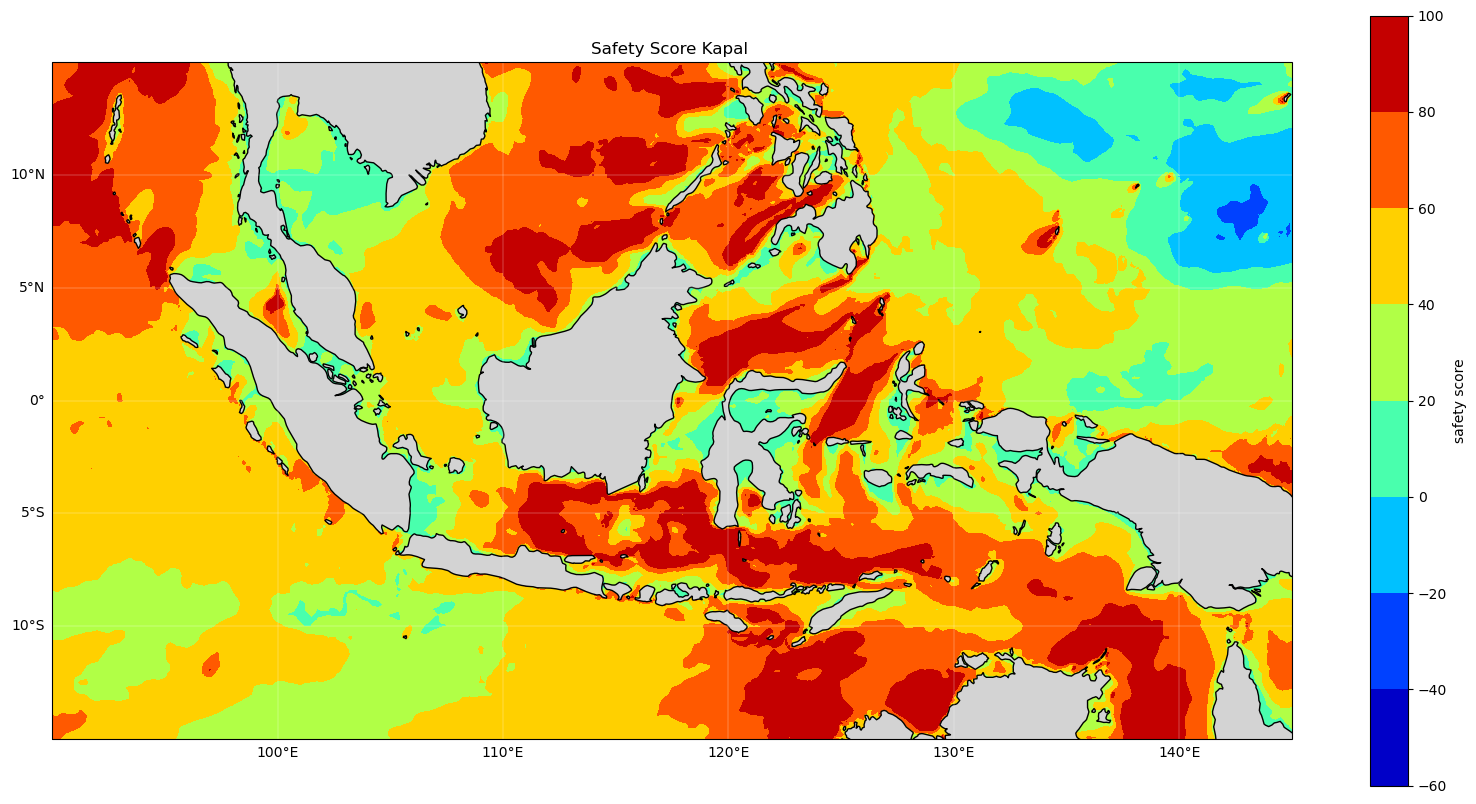

<xarray.DataArray (lat: 481, lon: 881)>
array([[6181.568  , 6144.0615 , 6106.561  , ...,  991.7772 ,  841.92694,
         690.2766 ],
       [6216.349  , 6180.257  , 6145.8516 , ...,  760.36273,  638.6709 ,
         539.6289 ],
       [6251.215  , 6212.983  , 6179.1304 , ...,  616.2441 ,  572.4525 ,
         594.69464],
       ...,
       [7161.6006 , 7184.1934 , 7217.009  , ..., 2467.677  , 2658.7803 ,
        2823.0059 ],
       [7154.835  , 7179.7104 , 7213.563  , ..., 2682.8242 , 2900.9927 ,
        3069.008  ],
       [7148.041  , 7182.2485 , 7216.327  , ..., 2792.8525 , 3054.335  ,
        3322.2    ]], dtype=float32)
Coordinates:
  * lon      (lon) float64 90.0 90.06 90.12 90.19 ... 144.8 144.9 144.9 145.0
  * lat      (lat) float64 -15.0 -14.94 -14.88 -14.81 ... 14.81 14.88 14.94 15.0
    time     datetime64[ns] 2024-02-05

In [ ]:
safetyscorespasi(wind, dflim['nelayan'].iloc[0], hs, dflim['nelayan'].iloc[1])*100

In [ ]:
safetyscorespasi(wind, dflim['tongkang'].iloc[0], hs, dflim['tongkang'].iloc[1])*100

In [ ]:
safetyscorespasi(wind, dflim['ferry'].iloc[0], hs, dflim['ferry'].iloc[1])*100

In [ ]:
safetyscorespasi(wind, dflim['kargo'].iloc[0], hs, dflim['kargo'].iloc[1])*100

# Data Preprocesing

## Survey Juru Mudi

In [ ]:
df = pd.read_csv('Survei Terhadap Nakhoda terkait Pentingnya Nilai Angka Keselamatan Kapal (Safety Score) untuk Keamanan Maritim (Jawaban) - Form Responses 1.csv')
df.head()

,Timestamp,Domisili Provinsi,Ukuran Kapal,Apakah pernah mengalami gangguan akibat cuaca di laut?,Parameter cuaca apakah yang paling berpengaruh?,"Jika pernah mengalami gangguan akibat Gelombang Tinggi, pada tinggi berapa meter aktivitas di kapal mulai terganggu?","Jika pernah mengalami gangguan akibat Angin Kencang, pada kecepatan berapa aktivitas di kapal mulai terganggu?","Jika pernah mengalami gangguan akibat Kecepatan Arus Kuat, pada kecepatan berapa aktivitas di kapal mulai terganggu?"
0,26/09/2023 12:05:03,Jawa Timur,1000 - 3000 GT,Pernah,Gelombang Tinggi,3.5 - 5 m,> 33 Knots,> 200 cm/s
1,26/09/2023 13:16:04,Nusa Tenggara Timur,1000 - 3000 GT,Pernah,Gelombang Tinggi,2.5 - 3.5 m,> 33 Knots,100 - 150 cm/s
2,26/09/2023 15:16:00,Sulawesi Selatan,1000 - 3000 GT,Pernah,Gelombang Tinggi,1.5 - 2.5 m,> 33 Knots,60 - 80 cm/s
3,26/09/2023 15:23:58,Sulawesi Selatan,1000 - 3000 GT,Pernah,Angin Kencang,2.5 - 3.5 m,28 - 33 Knots,100 - 150 cm/s
4,26/09/2023 15:30:09,DKI Jakarta,< 500 GT,Tidak Pernah,Gelombang Tinggi,0.2 m,> 33 Knots,80 - 100 cm/s


In [ ]:
df.columns[0]

'Timestamp'

In [ ]:
colrename = ['time', 'domisili', 'ship_size', 'gangguan', 'cuaca_berpengaruh', 'wave', 'wind', 'current']
dfrename = df
for i, col in enumerate(df.columns):
    print(f'{dfrename.columns[i]}--{colrename[i]}')
    dfrename = dfrename.rename(
        columns={
            f"{dfrename.columns[i]}":f"{colrename[i]}"
        }
    )
dfrename

Timestamp--time
Domisili Provinsi--domisili
Ukuran Kapal--ship_size
Apakah pernah mengalami gangguan akibat cuaca di laut?--gangguan
Parameter cuaca apakah yang paling berpengaruh?--cuaca_berpengaruh
Jika pernah mengalami gangguan akibat Gelombang Tinggi, pada tinggi berapa meter aktivitas di kapal mulai terganggu?--wave
Jika pernah mengalami gangguan akibat Angin Kencang, pada kecepatan berapa aktivitas di kapal mulai terganggu?--wind
Jika pernah mengalami gangguan akibat Kecepatan Arus Kuat, pada kecepatan berapa aktivitas di kapal mulai terganggu?--current


,time,domisili,ship_size,gangguan,cuaca_berpengaruh,wave,wind,current
0,26/09/2023 12:05:03,Jawa Timur,1000 - 3000 GT,Pernah,Gelombang Tinggi,3.5 - 5 m,> 33 Knots,> 200 cm/s
1,26/09/2023 13:16:04,Nusa Tenggara Timur,1000 - 3000 GT,Pernah,Gelombang Tinggi,2.5 - 3.5 m,> 33 Knots,100 - 150 cm/s
2,26/09/2023 15:16:00,Sulawesi Selatan,1000 - 3000 GT,Pernah,Gelombang Tinggi,1.5 - 2.5 m,> 33 Knots,60 - 80 cm/s
3,26/09/2023 15:23:58,Sulawesi Selatan,1000 - 3000 GT,Pernah,Angin Kencang,2.5 - 3.5 m,28 - 33 Knots,100 - 150 cm/s
4,26/09/2023 15:30:09,DKI Jakarta,< 500 GT,Tidak Pernah,Gelombang Tinggi,0.2 m,> 33 Knots,80 - 100 cm/s
5,26/09/2023 15:58:01,DKI Jakarta,< 500 GT,Pernah,Gelombang Tinggi,1.5 - 2.5 m,28 - 33 Knots,60 - 80 cm/s
6,26/09/2023 16:25:36,Sulawesi Selatan,1000 - 3000 GT,Pernah,Gelombang Tinggi,2.5 - 3.5 m,> 33 Knots,80 - 100 cm/s
7,26/09/2023 17:36:46,Jawa Barat,< 500 GT,Pernah,Gelombang Tinggi,1.0 - 1.5 m,4 - 6 Knots,100 - 150 cm/s
8,26/09/2023 18:23:43,DKI Jakarta,< 500 GT,Tidak Pernah,Gelombang Tinggi,0.2 m,1 - 3 Knots,30 - 45 cm/s
9,26/09/2023 18:38:44,Banten,< 500 GT,Pernah,Gelombang Tinggi,3.5 - 5 m,22 - 27 Knots,60 - 80 cm/s


In [ ]:
dfrename

,Timestamp,Domisili Provinsi,Ukuran Kapal,Apakah pernah mengalami gangguan akibat cuaca di laut?,Parameter cuaca apakah yang paling berpengaruh?,"Jika pernah mengalami gangguan akibat Gelombang Tinggi, pada tinggi berapa meter aktivitas di kapal mulai terganggu?","Jika pernah mengalami gangguan akibat Angin Kencang, pada kecepatan berapa aktivitas di kapal mulai terganggu?","Jika pernah mengalami gangguan akibat Kecepatan Arus Kuat, pada kecepatan berapa aktivitas di kapal mulai terganggu?"
0,26/09/2023 12:05:03,Jawa Timur,1000 - 3000 GT,Pernah,Gelombang Tinggi,3.5 - 5 m,> 33 Knots,> 200 cm/s
1,26/09/2023 13:16:04,Nusa Tenggara Timur,1000 - 3000 GT,Pernah,Gelombang Tinggi,2.5 - 3.5 m,> 33 Knots,100 - 150 cm/s
2,26/09/2023 15:16:00,Sulawesi Selatan,1000 - 3000 GT,Pernah,Gelombang Tinggi,1.5 - 2.5 m,> 33 Knots,60 - 80 cm/s
3,26/09/2023 15:23:58,Sulawesi Selatan,1000 - 3000 GT,Pernah,Angin Kencang,2.5 - 3.5 m,28 - 33 Knots,100 - 150 cm/s
4,26/09/2023 15:30:09,DKI Jakarta,< 500 GT,Tidak Pernah,Gelombang Tinggi,0.2 m,> 33 Knots,80 - 100 cm/s
5,26/09/2023 15:58:01,DKI Jakarta,< 500 GT,Pernah,Gelombang Tinggi,1.5 - 2.5 m,28 - 33 Knots,60 - 80 cm/s
6,26/09/2023 16:25:36,Sulawesi Selatan,1000 - 3000 GT,Pernah,Gelombang Tinggi,2.5 - 3.5 m,> 33 Knots,80 - 100 cm/s
7,26/09/2023 17:36:46,Jawa Barat,< 500 GT,Pernah,Gelombang Tinggi,1.0 - 1.5 m,4 - 6 Knots,100 - 150 cm/s
8,26/09/2023 18:23:43,DKI Jakarta,< 500 GT,Tidak Pernah,Gelombang Tinggi,0.2 m,1 - 3 Knots,30 - 45 cm/s
9,26/09/2023 18:38:44,Banten,< 500 GT,Pernah,Gelombang Tinggi,3.5 - 5 m,22 - 27 Knots,60 - 80 cm/s


In [ ]:
sorted([i for i in df['Ukuran Kapal'].unique()])

['1000 - 3000 GT', '3000 - 5000 GT', '500 - 1000 GT', '< 500 GT', '> 5000 GT']

### Sel

In [ ]:
# dfnel = df[(df['Ukuran Kapal'] == '< 500 GT') | (df['Ukuran Kapal'] == '500 - 1000 GT')]
dfnel = df[(df['Ukuran Kapal'] == '< 500 GT')]
# dfnel
dfnel.iloc[:, -1].sort_values()


7     100 - 150 cm/s
31      20 - 30 cm/s
8       30 - 45 cm/s
36      30 - 45 cm/s
35      30 - 45 cm/s
27      45 - 60 cm/s
47      45 - 60 cm/s
33      45 - 60 cm/s
24      45 - 60 cm/s
49      45 - 60 cm/s
30      45 - 60 cm/s
45      60 - 80 cm/s
40      60 - 80 cm/s
37      60 - 80 cm/s
32      60 - 80 cm/s
50      60 - 80 cm/s
22      60 - 80 cm/s
12      60 - 80 cm/s
9       60 - 80 cm/s
5       60 - 80 cm/s
19     80 - 100 cm/s
16     80 - 100 cm/s
39     80 - 100 cm/s
10     80 - 100 cm/s
4      80 - 100 cm/s
25        > 200 cm/s
Name: Jika pernah mengalami gangguan akibat Kecepatan Arus Kuat, pada kecepatan berapa aktivitas di kapal mulai terganggu?, dtype: object

In [ ]:
dftong = df[df['Ukuran Kapal'] == '1000 - 3000 GT']
dftong.iloc[:, -1].sort_values()

1     100 - 150 cm/s
3     100 - 150 cm/s
44    100 - 150 cm/s
11      45 - 60 cm/s
2       60 - 80 cm/s
23      60 - 80 cm/s
6      80 - 100 cm/s
38     80 - 100 cm/s
0         > 200 cm/s
Name: Jika pernah mengalami gangguan akibat Kecepatan Arus Kuat, pada kecepatan berapa aktivitas di kapal mulai terganggu?, dtype: object

In [ ]:
dffer = df[df['Ukuran Kapal'] == '3000 - 5000 GT']
dffer.iloc[:, -1].sort_values()

17    150 - 200 cm/s
15     80 - 100 cm/s
Name: Jika pernah mengalami gangguan akibat Kecepatan Arus Kuat, pada kecepatan berapa aktivitas di kapal mulai terganggu?, dtype: object

In [ ]:
dfkar = df[df['Ukuran Kapal'] == '> 5000 GT']
dfkar.iloc[:, -1].sort_values()

14     20 - 30 cm/s
18     20 - 30 cm/s
42     45 - 60 cm/s
43     45 - 60 cm/s
41     60 - 80 cm/s
46    80 - 100 cm/s
48    80 - 100 cm/s
26       > 200 cm/s
Name: Jika pernah mengalami gangguan akibat Kecepatan Arus Kuat, pada kecepatan berapa aktivitas di kapal mulai terganggu?, dtype: object

In [ ]:
1

In [ ]:
dfkar

,Timestamp,Domisili Provinsi,Ukuran Kapal,Apakah pernah mengalami gangguan akibat cuaca di laut?,Parameter cuaca apakah yang paling berpengaruh?,"Jika pernah mengalami gangguan akibat Gelombang Tinggi, pada tinggi berapa meter aktivitas di kapal mulai terganggu?","Jika pernah mengalami gangguan akibat Angin Kencang, pada kecepatan berapa aktivitas di kapal mulai terganggu?","Jika pernah mengalami gangguan akibat Kecepatan Arus Kuat, pada kecepatan berapa aktivitas di kapal mulai terganggu?"
14,26/09/2023 20:39:29,Banten,> 5000 GT,Pernah,Gelombang Tinggi,2.5 - 3.5 m,22 - 27 Knots,20 - 30 cm/s
18,27/09/2023 5:07:51,Jawa Timur,> 5000 GT,Pernah,Gelombang Tinggi,3.5 - 5 m,> 33 Knots,20 - 30 cm/s
26,27/09/2023 8:34:14,Jawa Timur,> 5000 GT,Pernah,Gelombang Tinggi,3.5 - 5 m,22 - 27 Knots,> 200 cm/s
41,27/09/2023 14:57:55,Jawa Barat,> 5000 GT,Pernah,Angin Kencang,1.5 - 2.5 m,> 33 Knots,60 - 80 cm/s
42,27/09/2023 15:01:56,Jawa Tengah,> 5000 GT,Pernah,Gelombang Tinggi,> 5 m,> 33 Knots,45 - 60 cm/s
43,27/09/2023 15:12:03,Jawa Tengah,> 5000 GT,Pernah,Gelombang Tinggi,2.5 - 3.5 m,17 - 21 Knots,45 - 60 cm/s
46,28/09/2023 1:50:18,Banten,> 5000 GT,Pernah,Kecepatan Arus Kuat,1.5 - 2.5 m,11 - 16 Knots,80 - 100 cm/s
48,28/09/2023 10:43:38,DKI Jakarta,> 5000 GT,Pernah,Gelombang Tinggi,1.5 - 2.5 m,17 - 21 Knots,80 - 100 cm/s


## Generate data

In [ ]:
treshold = {
    'Nelayan': {'Angin': 15, 'Gelombang': 1.25, 'Arus': 110},
    'Tongkang': {'Angin': 16, 'Gelombang': 1.5, 'Arus': 122.5},
    'Ferry': {'Angin': 21, 'Gelombang': 2.5, 'Arus': 140},
    'Kapal Besar': {'Angin': 27, 'Gelombang': 4.0, 'Arus': 150}
}

def generate_data(treshold, n):
    data = {'Tipe Kapal': [], 'Angin': [], 'Gelombang': [], 'Arus': [], 'Kejadian': []}
    for tipe_kapal, thres in treshold.items():
        for _ in range(n):
            angin = np.random.uniform(0, 60)
            gelombang = np.random.uniform(0, 9)
            arus = np.random.uniform(0, 300)
            kejadian = 1 if (angin > thres['Angin'] or gelombang > thres['Gelombang'] or arus > thres['Arus']) else 0
            data['Tipe Kapal'].append(tipe_kapal)
            data['Angin'].append(angin)
            data['Gelombang'].append(gelombang)
            data['Arus'].append(arus)
            data['Kejadian'].append(kejadian)
    return pd.DataFrame(data)

# Generate data
n = 1000
# data = generate_data(treshold, n) # no need to run this line again, we just need to load the existing previous generated data
# with open('dataset.pkl', 'wb') as f:
#     pickle.dump(data, f)
# print(data.head())

In [ ]:
with open('dataset.pkl', 'rb') as f:
    data = pickle.load(f)

data

,Tipe Kapal,Angin,Gelombang,Arus,Kejadian
0,Nelayan,4.855456,2.597203,104.211183,1
1,Nelayan,42.093471,0.481493,57.858922,1
2,Nelayan,28.206176,4.771092,87.392518,1
3,Nelayan,46.337091,8.175937,232.813451,1
4,Nelayan,25.740321,3.239733,81.056514,1
...,...,...,...,...,...
3995,Kapal Besar,26.031900,2.478189,202.902448,1
3996,Kapal Besar,46.011082,0.016732,238.078979,1
3997,Kapal Besar,28.819542,1.562451,101.337120,1
3998,Kapal Besar,45.135441,5.004683,74.121228,1


## Check distribusi data

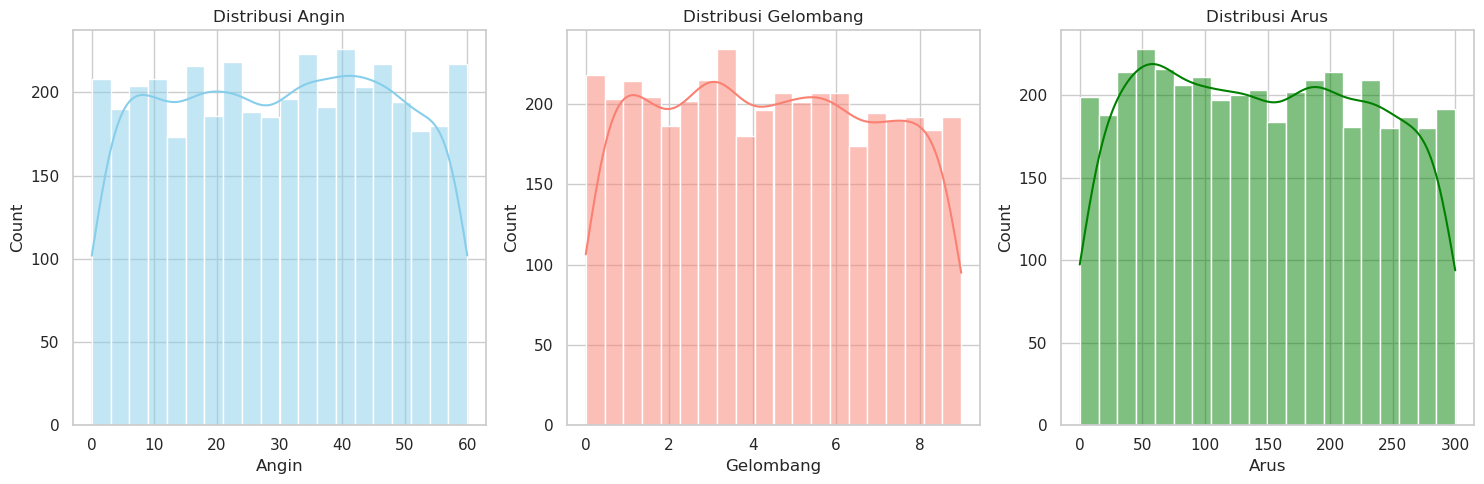

In [ ]:
# Set tema visual seaborn
sns.set(style="whitegrid")

# Visualisasi distribusi untuk setiap variabel
plt.figure(figsize=(15, 5))

# Distribusi Angin
plt.subplot(1, 3, 1)
sns.histplot(data['Angin'], kde=True, color='skyblue', bins=20)
plt.title('Distribusi Angin')

# Distribusi Gelombang
plt.subplot(1, 3, 2)
sns.histplot(data['Gelombang'], kde=True, color='salmon', bins=20)
plt.title('Distribusi Gelombang')

# Distribusi Arus
plt.subplot(1, 3, 3)
sns.histplot(data['Arus'], kde=True, color='green', bins=20)
plt.title('Distribusi Arus')

plt.tight_layout()
plt.show()


In [ ]:
# Hitung skewness dan kurtosis untuk masing-masing variabel
skewness_angin = data['Angin'].skew()
kurtosis_angin = data['Angin'].kurtosis()

skewness_gelombang = data['Gelombang'].skew()
kurtosis_gelombang = data['Gelombang'].kurtosis()

skewness_arus = data['Arus'].skew()
kurtosis_arus = data['Arus'].kurtosis()

print("Skewness dan kurtosis untuk setiap variabel:")
print(f"Angin: Skewness = {skewness_angin}, Kurtosis = {kurtosis_angin}")
print(f"Gelombang: Skewness = {skewness_gelombang}, Kurtosis = {kurtosis_gelombang}")
print(f"Arus: Skewness = {skewness_arus}, Kurtosis = {kurtosis_arus}")

Skewness dan kurtosis untuk setiap variabel:
Angin: Skewness = -0.012070637094294855, Kurtosis = -1.1905083672313017
Gelombang: Skewness = 0.03906896481019808, Kurtosis = -1.1823044160540643
Arus: Skewness = 0.050821061676317864, Kurtosis = -1.187877958240348


In [ ]:
from scipy.stats import shapiro

# Lakukan uji Shapiro-Wilk untuk setiap variabel
shapiro_test_angin = shapiro(data['Angin'])
shapiro_test_gelombang = shapiro(data['Gelombang'])
shapiro_test_arus = shapiro(data['Arus'])

# Tampilkan hasil uji Shapiro-Wilk
print("Hasil uji Shapiro-Wilk untuk setiap variabel:")
print(f"Angin: Statistik uji = {shapiro_test_angin[0]}, p-value = {round(shapiro_test_angin[1], 10)}")
print(f"Gelombang: Statistik uji = {shapiro_test_gelombang[0]}, p-value = {shapiro_test_gelombang[1]}")
print(f"Arus: Statistik uji = {shapiro_test_arus[0]}, p-value = {shapiro_test_arus[1]}")


Hasil uji Shapiro-Wilk untuk setiap variabel:
Angin: Statistik uji = 0.9557154178619385, p-value = 0.0
Gelombang: Statistik uji = 0.9560453295707703, p-value = 3.947549169693237e-33
Arus: Statistik uji = 0.9562810659408569, p-value = 4.670955740028965e-33


# Build logit models

## Build 4 logistic regression models based on ship category

In [ ]:
def build_logistic_regression_model(df, tipe_kapal):
    subset_data = df[df['Tipe Kapal'] == tipe_kapal]
    X = subset_data[['Angin', 'Gelombang', 'Arus']]
    X = sm.add_constant(X)
    y = subset_data['Kejadian']
    model = sm.Logit(y, X)
    result = model.fit()
    predictions = result.predict(X)
    print(f"\nModel Regresi Logistik untuk Tipe Kapal: {tipe_kapal}")
    print(result.summary())
    print("\nClassification Report:")
    print(classification_report(y, predictions.round(), target_names=['Tidak Gangguan', 'Gangguan']))
    return model

models = {}
for tipe_kapal in data['Tipe Kapal'].unique():
    model = build_logistic_regression_model(data, tipe_kapal)
    models[tipe_kapal] = model

Optimization terminated successfully.
         Current function value: 0.015824
         Iterations 14

Model Regresi Logistik untuk Tipe Kapal: Nelayan
                           Logit Regression Results                           
Dep. Variable:               Kejadian   No. Observations:                 1000
Model:                          Logit   Df Residuals:                      996
Method:                           MLE   Df Model:                            3
Date:                Fri, 09 Feb 2024   Pseudo R-squ.:                  0.7387
Time:                        23:20:15   Log-Likelihood:                -15.824
converged:                       True   LL-Null:                       -60.548
Covariance Type:            nonrobust   LLR p-value:                 2.878e-19
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -7.2818      2.296     -3.171      0.002   

In [ ]:
# save and open
# with open('logit_models.pkl', 'wb') as f:
#     pickle.dump(models, f)
# with open('logit_models.pkl', 'rb') as f:
#     models = pickle.load(f)

In [ ]:
def display_regression_equation(model):
    coefficients = model.params

    equation = "Persamaan Regresi Logistik:\n"
    for i, (coef_name, coef_value) in enumerate(coefficients.items()):
        if i == 0:
            equation += f"Probability = {coef_value:.4f} (intercept)"
        else:
            equation += f" + {coef_value:.4f} * {coef_name}"
    print(equation)

for tipe_kapal, model in models.items():
    print(f"\nPersamaan Regresi Logistik untuk Tipe Kapal: {tipe_kapal}")
    display_regression_equation(model)

Optimization terminated successfully.
         Current function value: 0.015824
         Iterations 14

Persamaan Regresi Logistik untuk Tipe Kapal: Nelayan
Persamaan Regresi Logistik:
Probability = -7.2818 (intercept) + 0.2851 * Angin + 2.9762 * Gelombang + 0.0425 * Arus
Optimization terminated successfully.
         Current function value: 0.022059
         Iterations 13

Persamaan Regresi Logistik untuk Tipe Kapal: Tongkang
Persamaan Regresi Logistik:
Probability = -7.4916 (intercept) + 0.2564 * Angin + 2.7330 * Gelombang + 0.0432 * Arus
Optimization terminated successfully.
         Current function value: 0.039294
         Iterations 12

Persamaan Regresi Logistik untuk Tipe Kapal: Ferry
Persamaan Regresi Logistik:
Probability = -8.5064 (intercept) + 0.2840 * Angin + 2.1571 * Gelombang + 0.0320 * Arus
Optimization terminated successfully.
         Current function value: 0.129179
         Iterations 10

Persamaan Regresi Logistik untuk Tipe Kapal: Kapal Besar
Persamaan Regresi Log

## Coba inputan baru

In [ ]:
def predict_probability_new_data(model, input_data):
    input_data = sm.add_constant(input_data)
    predictions = model.predict(input_data)
    return predictions

new_input = {
    'Angin': [25, 18, 20],
    'Gelombang': [2, 3.5, 1.8],
    'Arus': [120, 100, 140]
}

for tipe_kapal, model in models.items():
    predictions = predict_probability_new_data(model, pd.DataFrame(new_input))
    print(f"\nPrediksi Probabilitas Kejadian untuk Tipe Kapal: {tipe_kapal}")
    print(predictions)

Optimization terminated successfully.
         Current function value: 0.015824
         Iterations 14

Prediksi Probabilitas Kejadian untuk Tipe Kapal: Nelayan
0    0.999982
1    0.999996
2    0.999941
dtype: float64
Optimization terminated successfully.
         Current function value: 0.022059
         Iterations 13

Prediksi Probabilitas Kejadian untuk Tipe Kapal: Tongkang
0    0.999930
1    0.999983
2    0.999816
dtype: float64
Optimization terminated successfully.
         Current function value: 0.039294
         Iterations 12

Prediksi Probabilitas Kejadian untuk Tipe Kapal: Ferry
0    0.998828
1    0.999361
2    0.996072
dtype: float64
Optimization terminated successfully.
         Current function value: 0.129179
         Iterations 10

Prediksi Probabilitas Kejadian untuk Tipe Kapal: Kapal Besar
0    0.864539
1    0.880079
2    0.812236
dtype: float64


# Implementasi ke SICM

## Load data

In [ ]:
with open('logit_models.pkl', 'rb') as f:
    models = pickle.load(f)

In [ ]:
# Data sample
path2fileww3 = '/data/share/output/netcdf/ww3gfs/2024/02/w3g_hires_20240205_0000.nc'
path2filefvcom = '/data/share/output/netcdf/fvcom/2024/02/InaFlows_20240205_0000.nc'

In [ ]:
ww3 = xr.open_dataset(path2fileww3)
fvcom = xr.open_dataset(path2filefvcom)

windmag = np.sqrt(np.square(ww3.uwnd.isel(time=0)) + np.square(ww3.vwnd.isel(time=0)))
swh = ww3.hs.isel(time=0)
current = np.sqrt(np.square(fvcom.u.isel(time=0, depth=0)) + np.square(fvcom.v.isel(time=0, depth=0)))

regridder = xe.Regridder(current, swh, 'bilinear') # regrid fvcom to ww3
current_regrid = regridder(current)

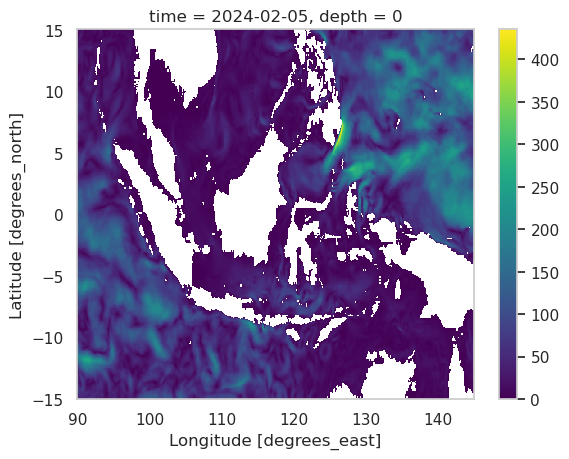

In [ ]:
test = swh*current_regrid
test.plot()

## Make a prediction

In [ ]:
wi_array = windmag.values
gelombang_array = swh.values
arus_array = current_regrid.values

input_data = np.column_stack((angin_array.flatten(), gelombang_array.flatten(), arus_array.flatten()))

def predict(input_data, model):
    z = np.dot(input_data, model.params[1:]) + model.params[0]
    prob = 1 / (1 + np.exp(-z))
    return prob

predictions = {}
for tipe_kapal, model in models.items():
    # Lakukan prediksi probabilitas untuk setiap tipe kapal
    predictions[tipe_kapal] = predict(input_data, model)

## Store predictions to dataset

In [ ]:
def predictions_to_dataset(predictions, input_data):
    lat = input_data['lat']
    lon = input_data['lon']
    data_vars = {}
    for tipe_kapal, pred_prob in predictions.items():
        reshaped_pred = pred_prob.reshape((len(lat), len(lon)))
        data_vars[tipe_kapal] = (['lat', 'lon'], (1-reshaped_pred)*100)
    dataset = xr.Dataset(data_vars, coords={'lat': lat, 'lon': lon})
    return dataset

pred_dataset = predictions_to_dataset(predictions, swh)
pred_dataset

<xarray.Dataset>
Dimensions:      (lat: 481, lon: 881)
Coordinates:
  * lat          (lat) float64 -15.0 -14.94 -14.88 -14.81 ... 14.88 14.94 15.0
    time         datetime64[ns] 2024-02-05
  * lon          (lon) float64 90.0 90.06 90.12 90.19 ... 144.9 144.9 145.0
Data variables:
    Nelayan      (lat, lon) float64 12.08 12.4 12.98 ... 0.04168 0.051 0.06467
    Tongkang     (lat, lon) float64 25.36 25.88 26.86 ... 0.17 0.2047 0.2553
    Ferry        (lat, lon) float64 73.05 73.62 74.51 75.37 ... 1.72 1.991 2.364
    Kapal Besar  (lat, lon) float64 96.17 96.23 96.34 ... 62.69 64.56 66.88

# Plotting

In [ ]:
def plot_map_vec(lat_data, lon_data, latlon_int, colormap, level, magnitude, u_comp, v_comp, skip, scale, map_title, legend_title):
    fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 10), dpi=300)
    ax.add_feature(BORDERS, linewidth=1)
    ax.add_feature(STATES, linewidth=1)
    ax.add_feature(LAND, edgecolor='black', facecolor='lightgray', zorder=1)

    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='w')
    gl.xlabels_top = False
    gl.ylabels_right = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}

    plotmap = ax.contourf(lon_data, lat_data, magnitude, cmap=colormap, levels=level, transform=ccrs.PlateCarree(), zorder=0)
    ax.quiver(lon_data[::skip], lat_data[::skip], u_comp[::skip, ::skip], v_comp[::skip, ::skip], units='inches', scale=scale, pivot='mid', width=0.015, transform=ccrs.PlateCarree(), zorder=0)

    col_bar = plt.colorbar(plotmap, ax=ax, orientation='horizontal', pad=0.05)
    col_bar.ax.tick_params(labelsize=15)
    col_bar.set_label(legend_title, fontsize=15)
    plt.title(map_title, fontsize=18)

    plt.show()

def plot_map_mag(lat_data, lon_data, latlon_int, colormap, level, magnitude, map_title, legend_title):
    fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 10), dpi=300)
    # Plot the coastline, borders, and land
    ax.add_feature(BORDERS, linewidth=1)
    ax.add_feature(STATES, linewidth=1)
    ax.add_feature(LAND, edgecolor='black', facecolor='lightgray', zorder=1)

    # Plot parallels and meridians
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='w')
    gl.xlabels_top = False
    gl.ylabels_right = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}

    plotmap = ax.contourf(lon_data, lat_data, magnitude, cmap=colormap, levels=level, transform=ccrs.PlateCarree(), zorder=0)

    col_bar = plt.colorbar(plotmap, ax=ax, orientation='horizontal', pad=0.05)
    col_bar.ax.tick_params(labelsize=15)
    col_bar.set_label(legend_title, fontsize=15)
    plt.title(map_title, fontsize=18)

    plt.show()

## SWH

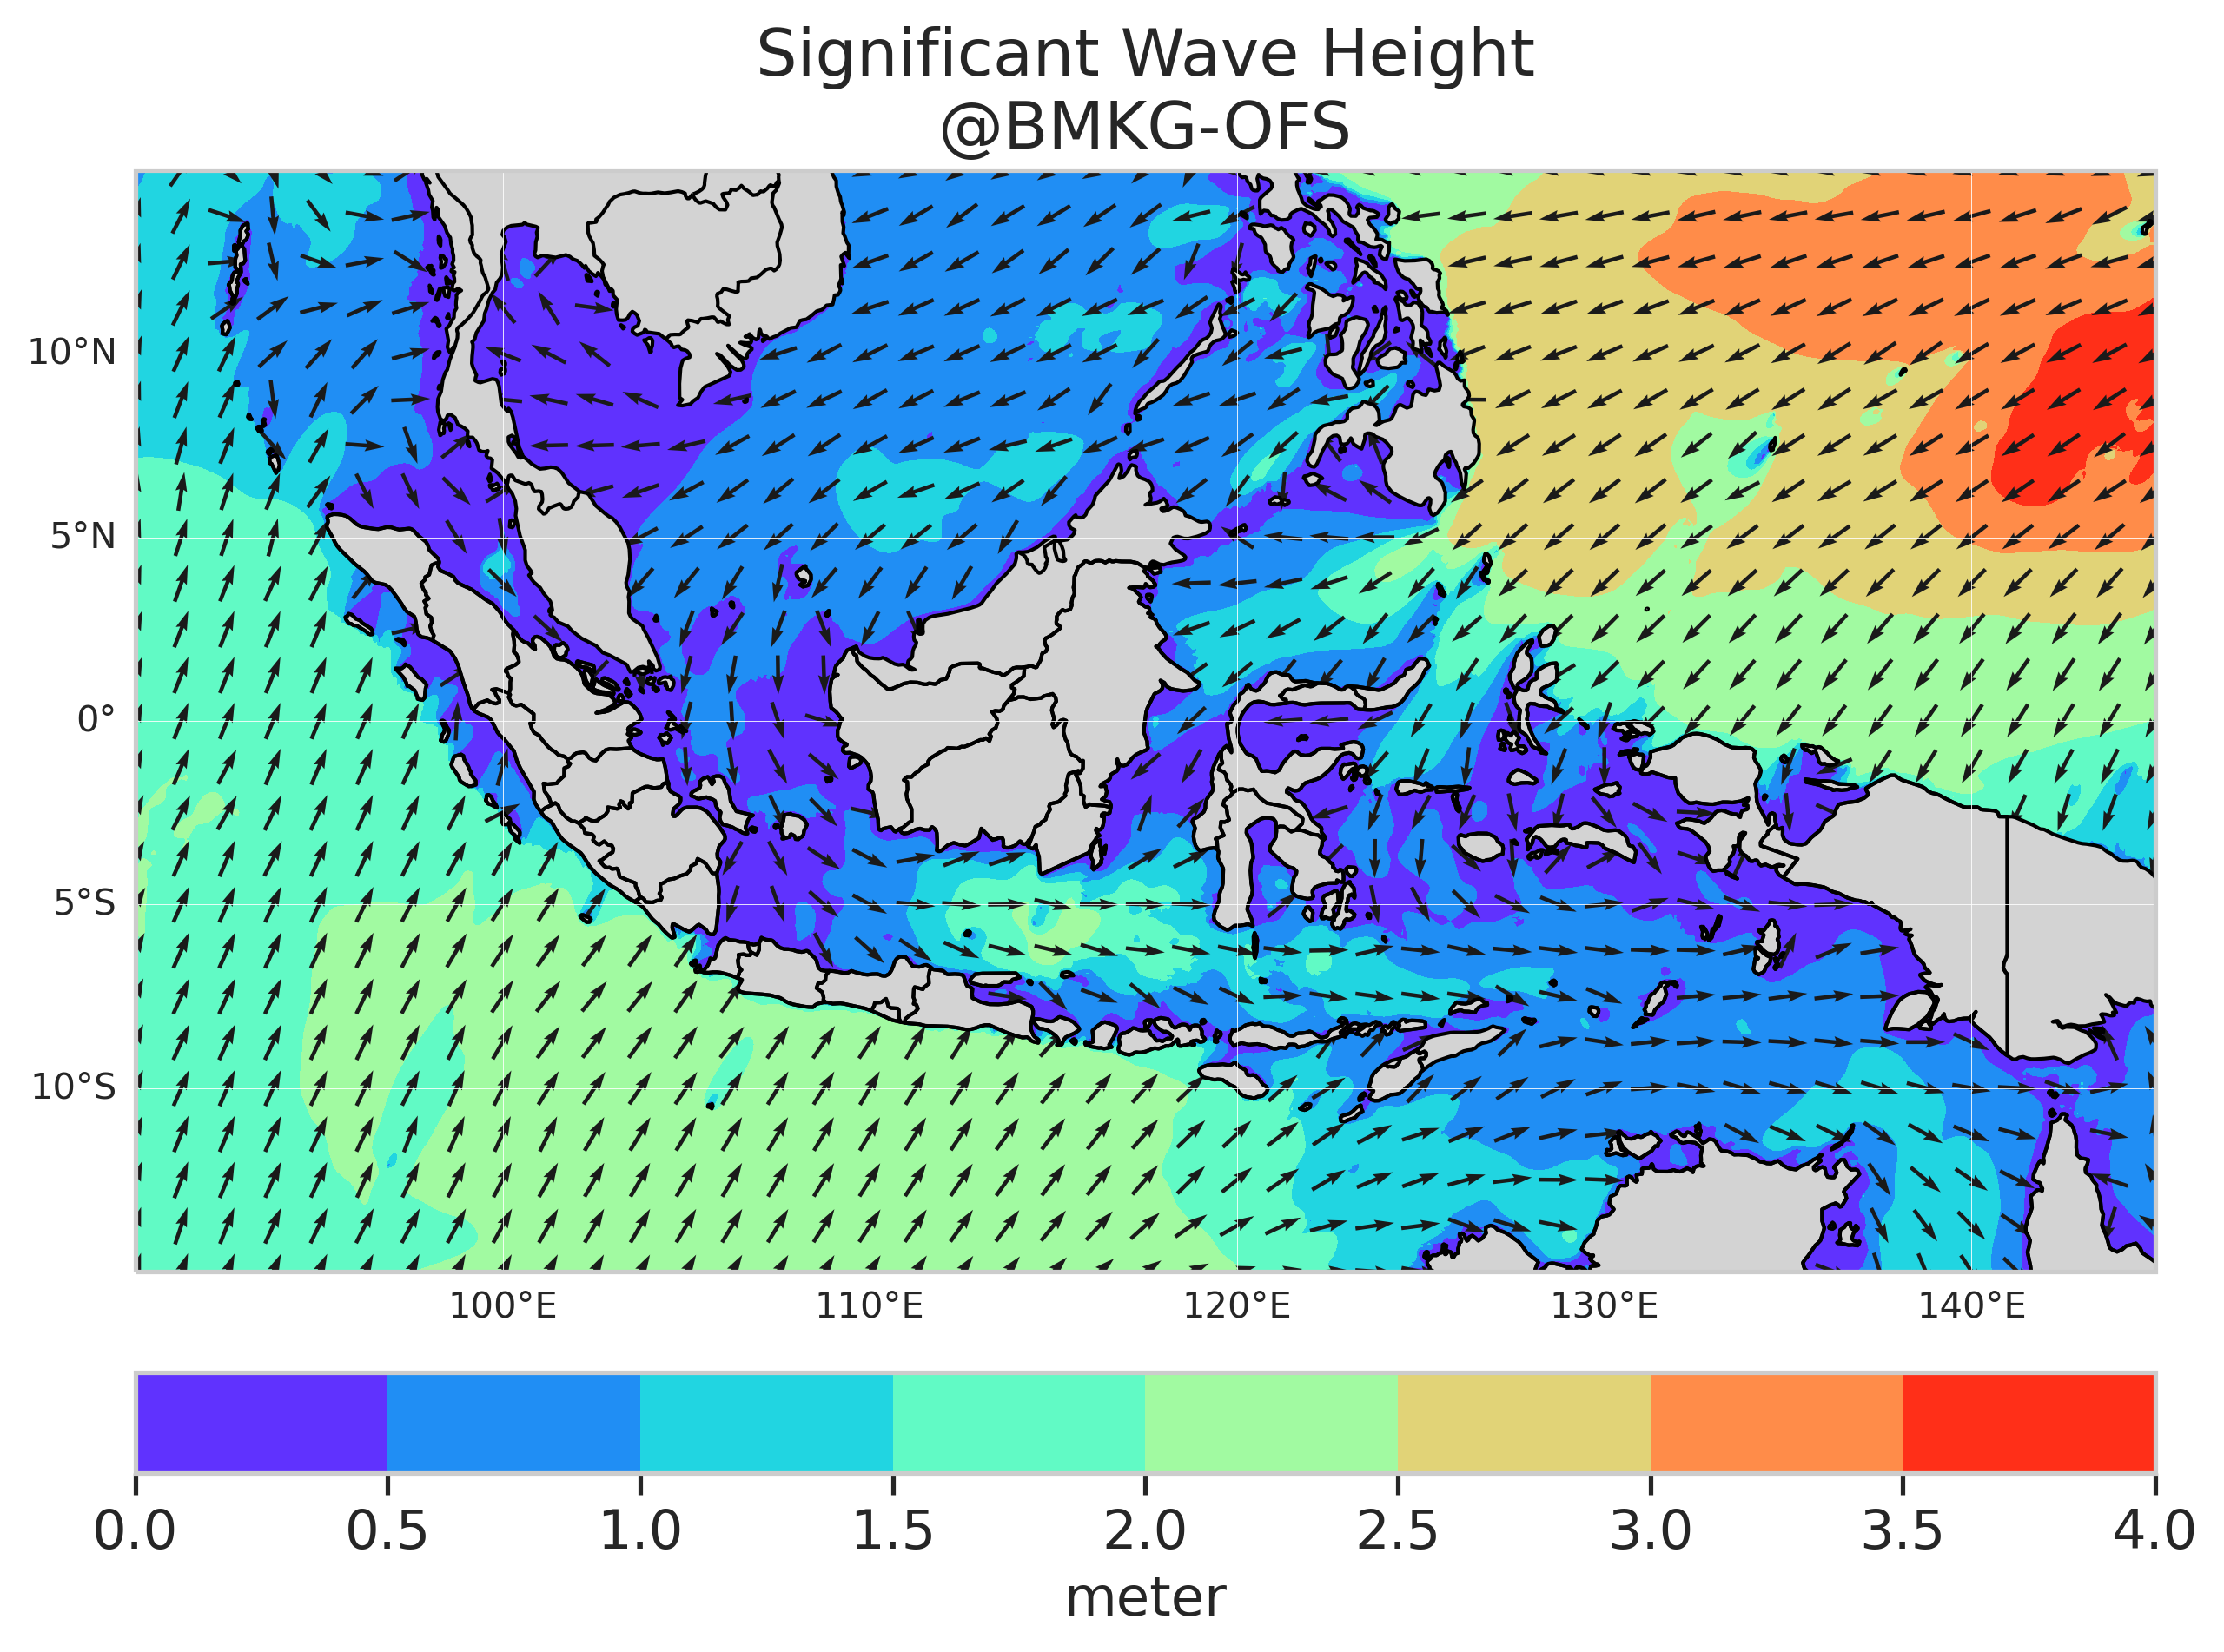

In [ ]:
skip = 15
wave_lvl = np.arange(0, 4.5, 0.5)
cmap_wave = 'rainbow'
arw_int = 20
arw_scale = 10
map_title = 'Significant Wave Height\n@BMKG-OFS'
legend_title = 'meter'
plot_map_vec(ww3.lat, ww3.lon, 5, cmap_wave, wave_lvl, ww3.hs.isel(time=0), 1.5*np.cos(np.deg2rad(dset.dir.isel(time=0))), 1.5*np.sin(np.deg2rad(ww3.dir.isel(time=0))), arw_int, arw_scale, map_title, legend_title)

## Wind

/root/mambaforge/lib/python3.10/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/root/mambaforge/lib/python3.10/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


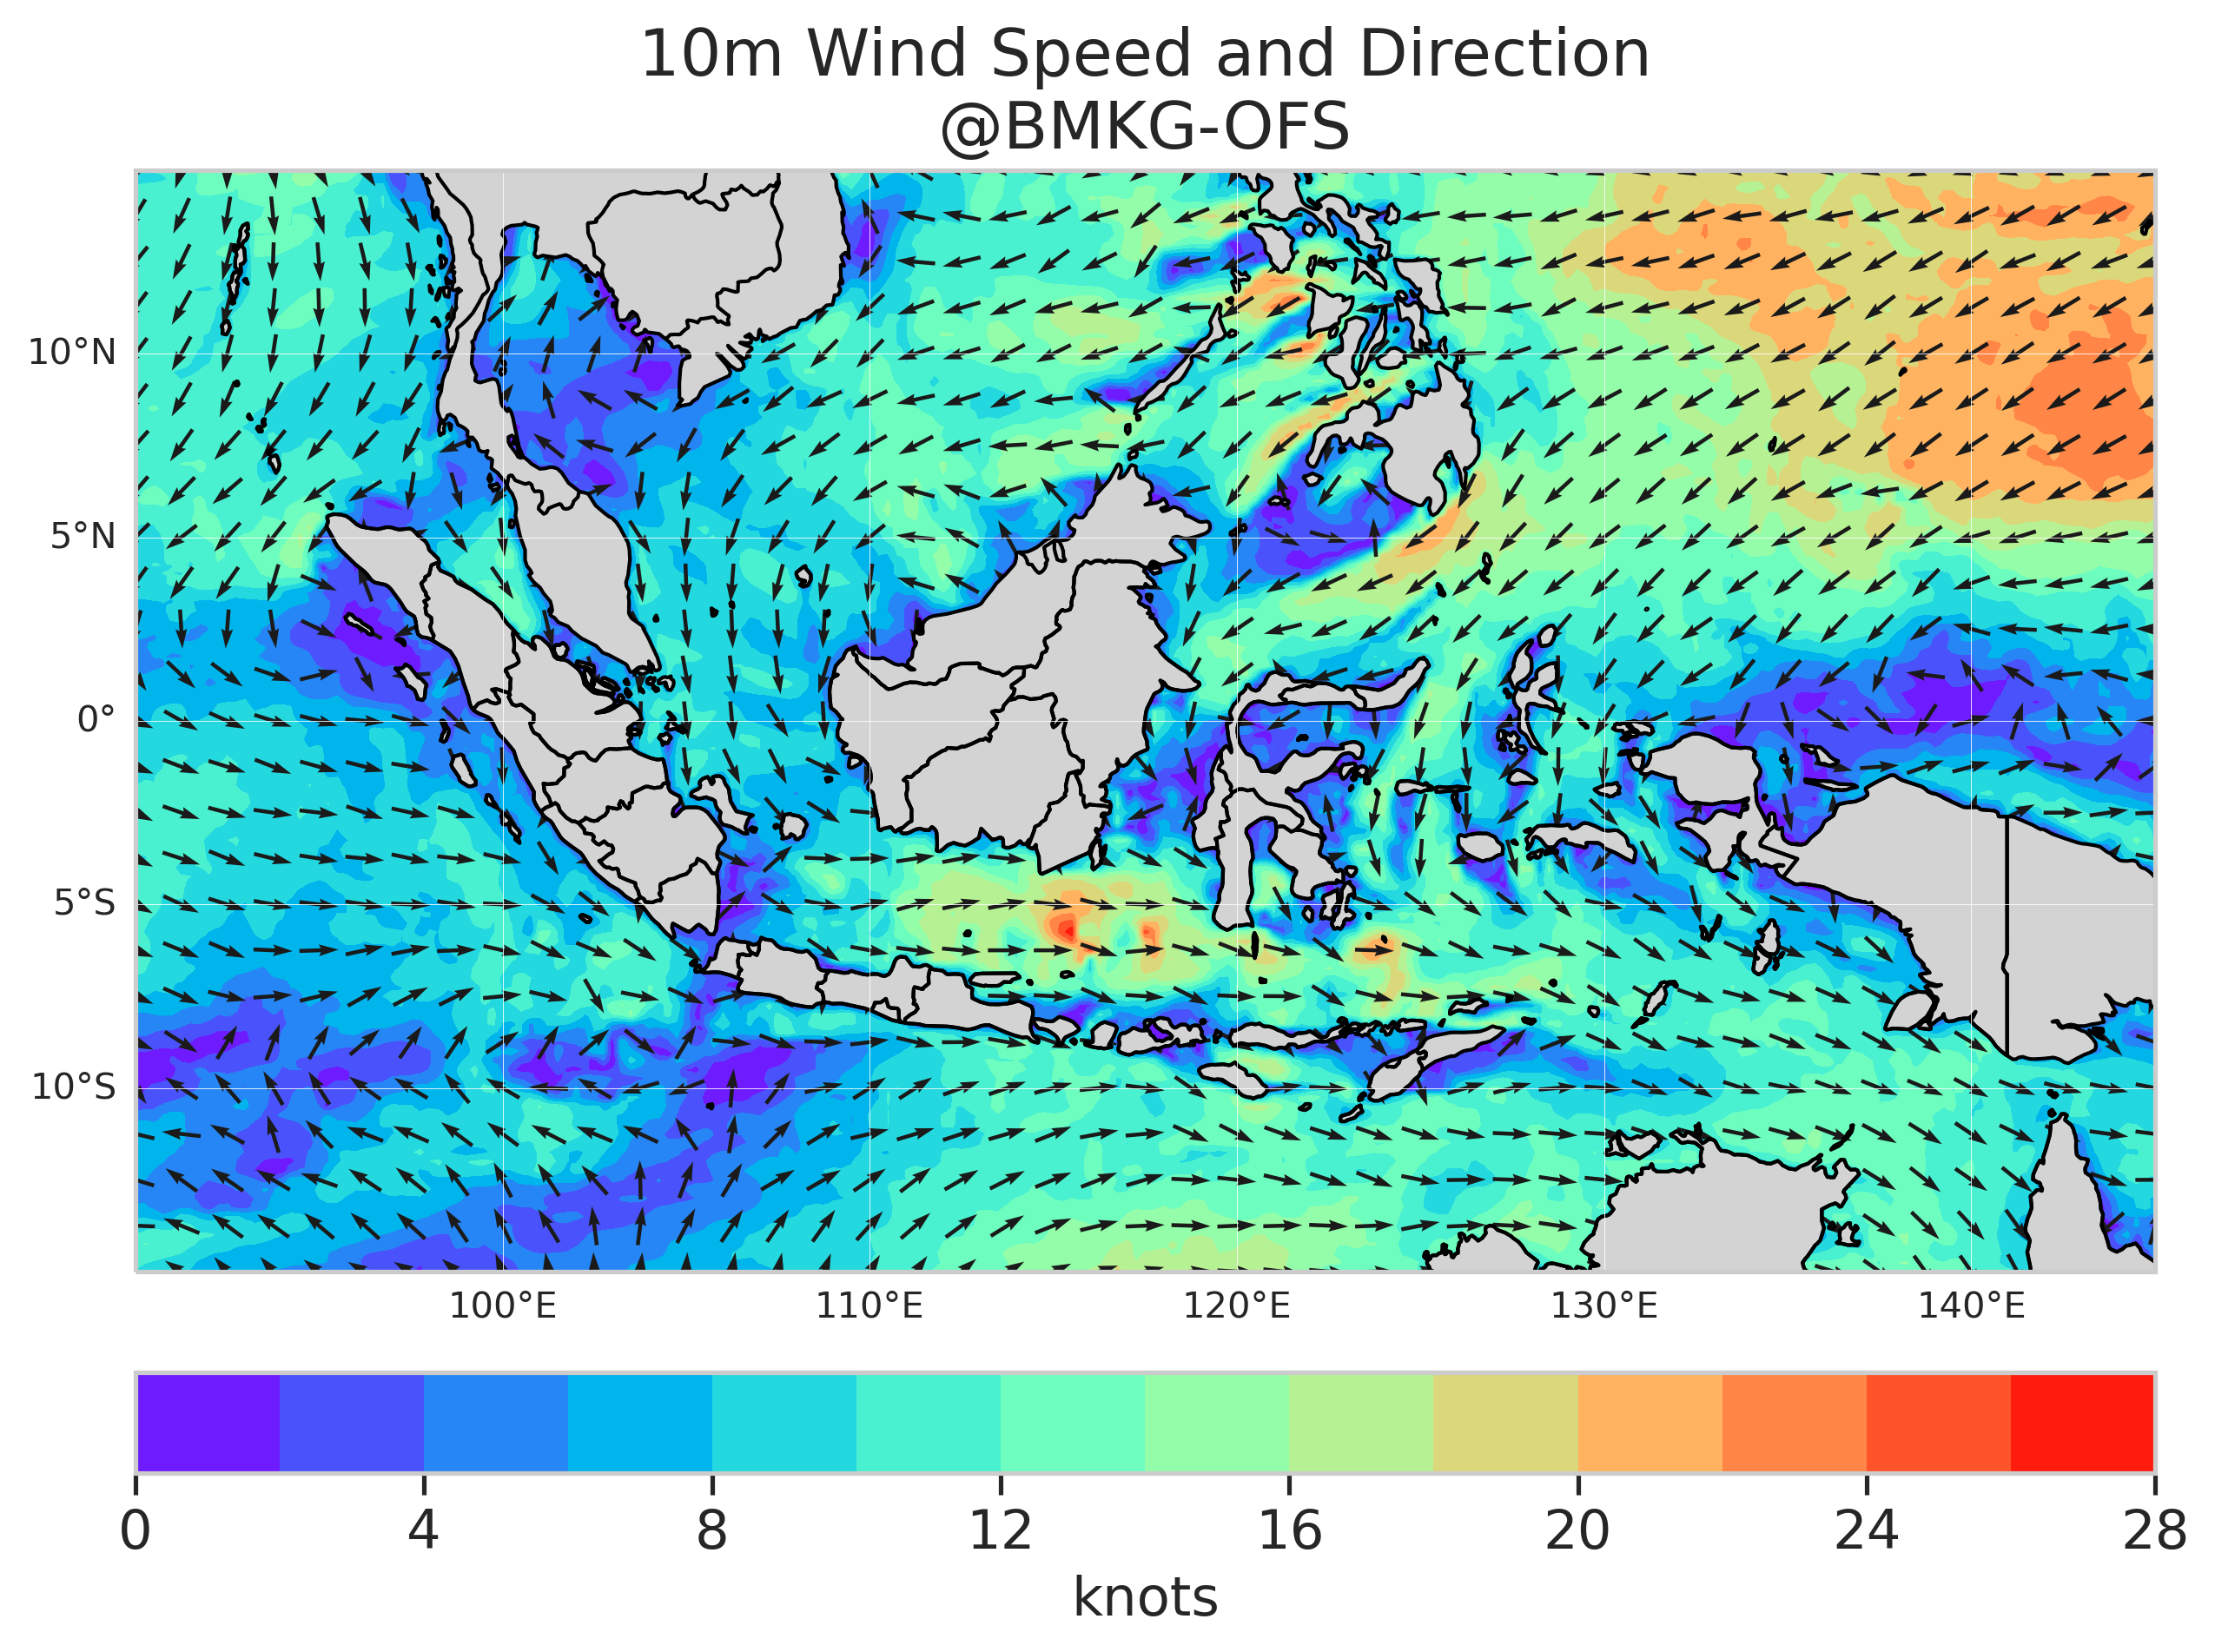

In [ ]:
wind_lvl = np.arange(0, 30, 2)
cmap_wave = 'rainbow'
arw_int = 20
arw_scale = 10
map_title = '10m Wind Speed and Direction\n@BMKG-OFS'
legend_title = 'knots'
wind_mag = windmag
plot_map_vec(ww3.lat, ww3.lon, 5, cmap_wave, wind_lvl, wind_mag, 1.5*ww3.uwnd.isel(time=0)/wind_mag, 1.5*ww3.vwnd.isel(time=0)/wind_mag, arw_int, arw_scale, map_title, legend_title)

## Current

/root/mambaforge/lib/python3.10/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/root/mambaforge/lib/python3.10/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


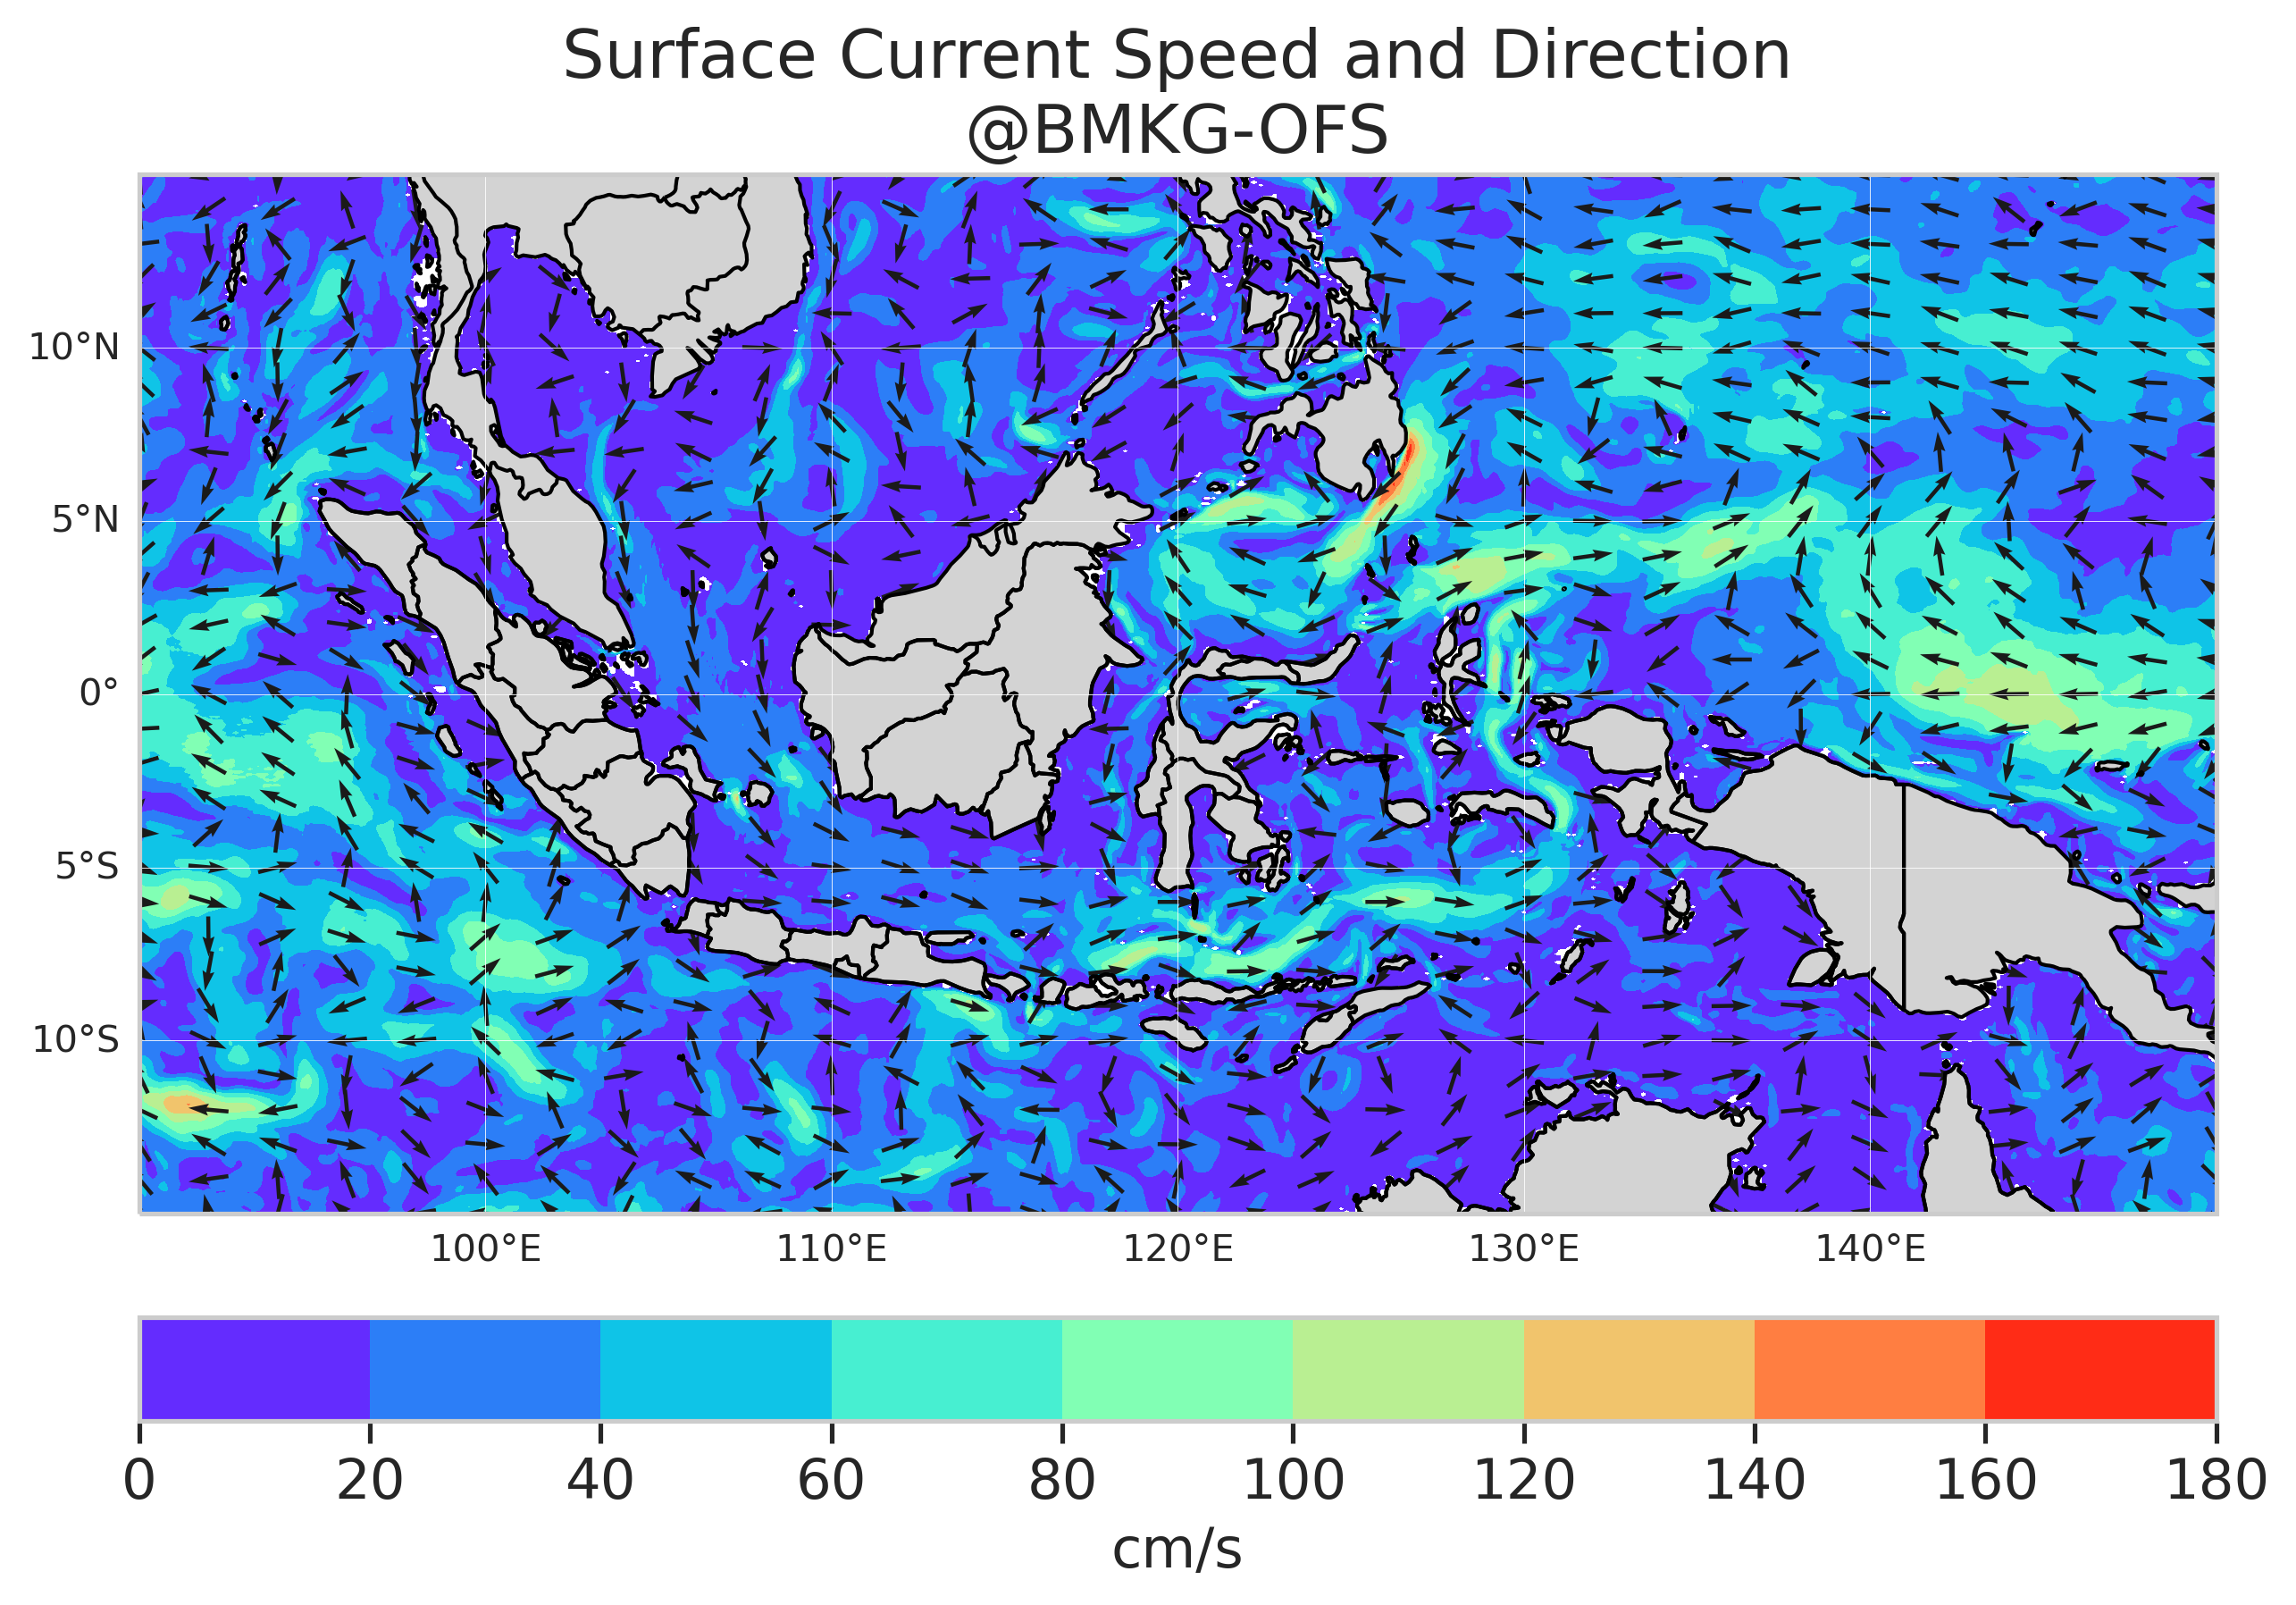

In [ ]:
wind_lvl = np.arange(0, 200, 20)
cmap_wave = 'rainbow'
arw_int = 25
arw_scale = 10
map_title = 'Surface Current Speed and Direction\n@BMKG-OFS'
legend_title = 'cm/s'
current = current.sel(lat=slice(-15, 15), lon=slice(90, 150))
fvcom = fvcom.sel(lat=slice(-15, 15), lon=slice(90, 150))
plot_map_vec(fvcom.lat, fvcom.lon, 5, cmap_wave, wind_lvl, current, 1.5*fvcom.u.isel(time=0, depth=0)/current, 1.5*fvcom.v.isel(time=0, depth=0)/current, arw_int, arw_scale, map_title, legend_title)

## Safety score

### Nelayan

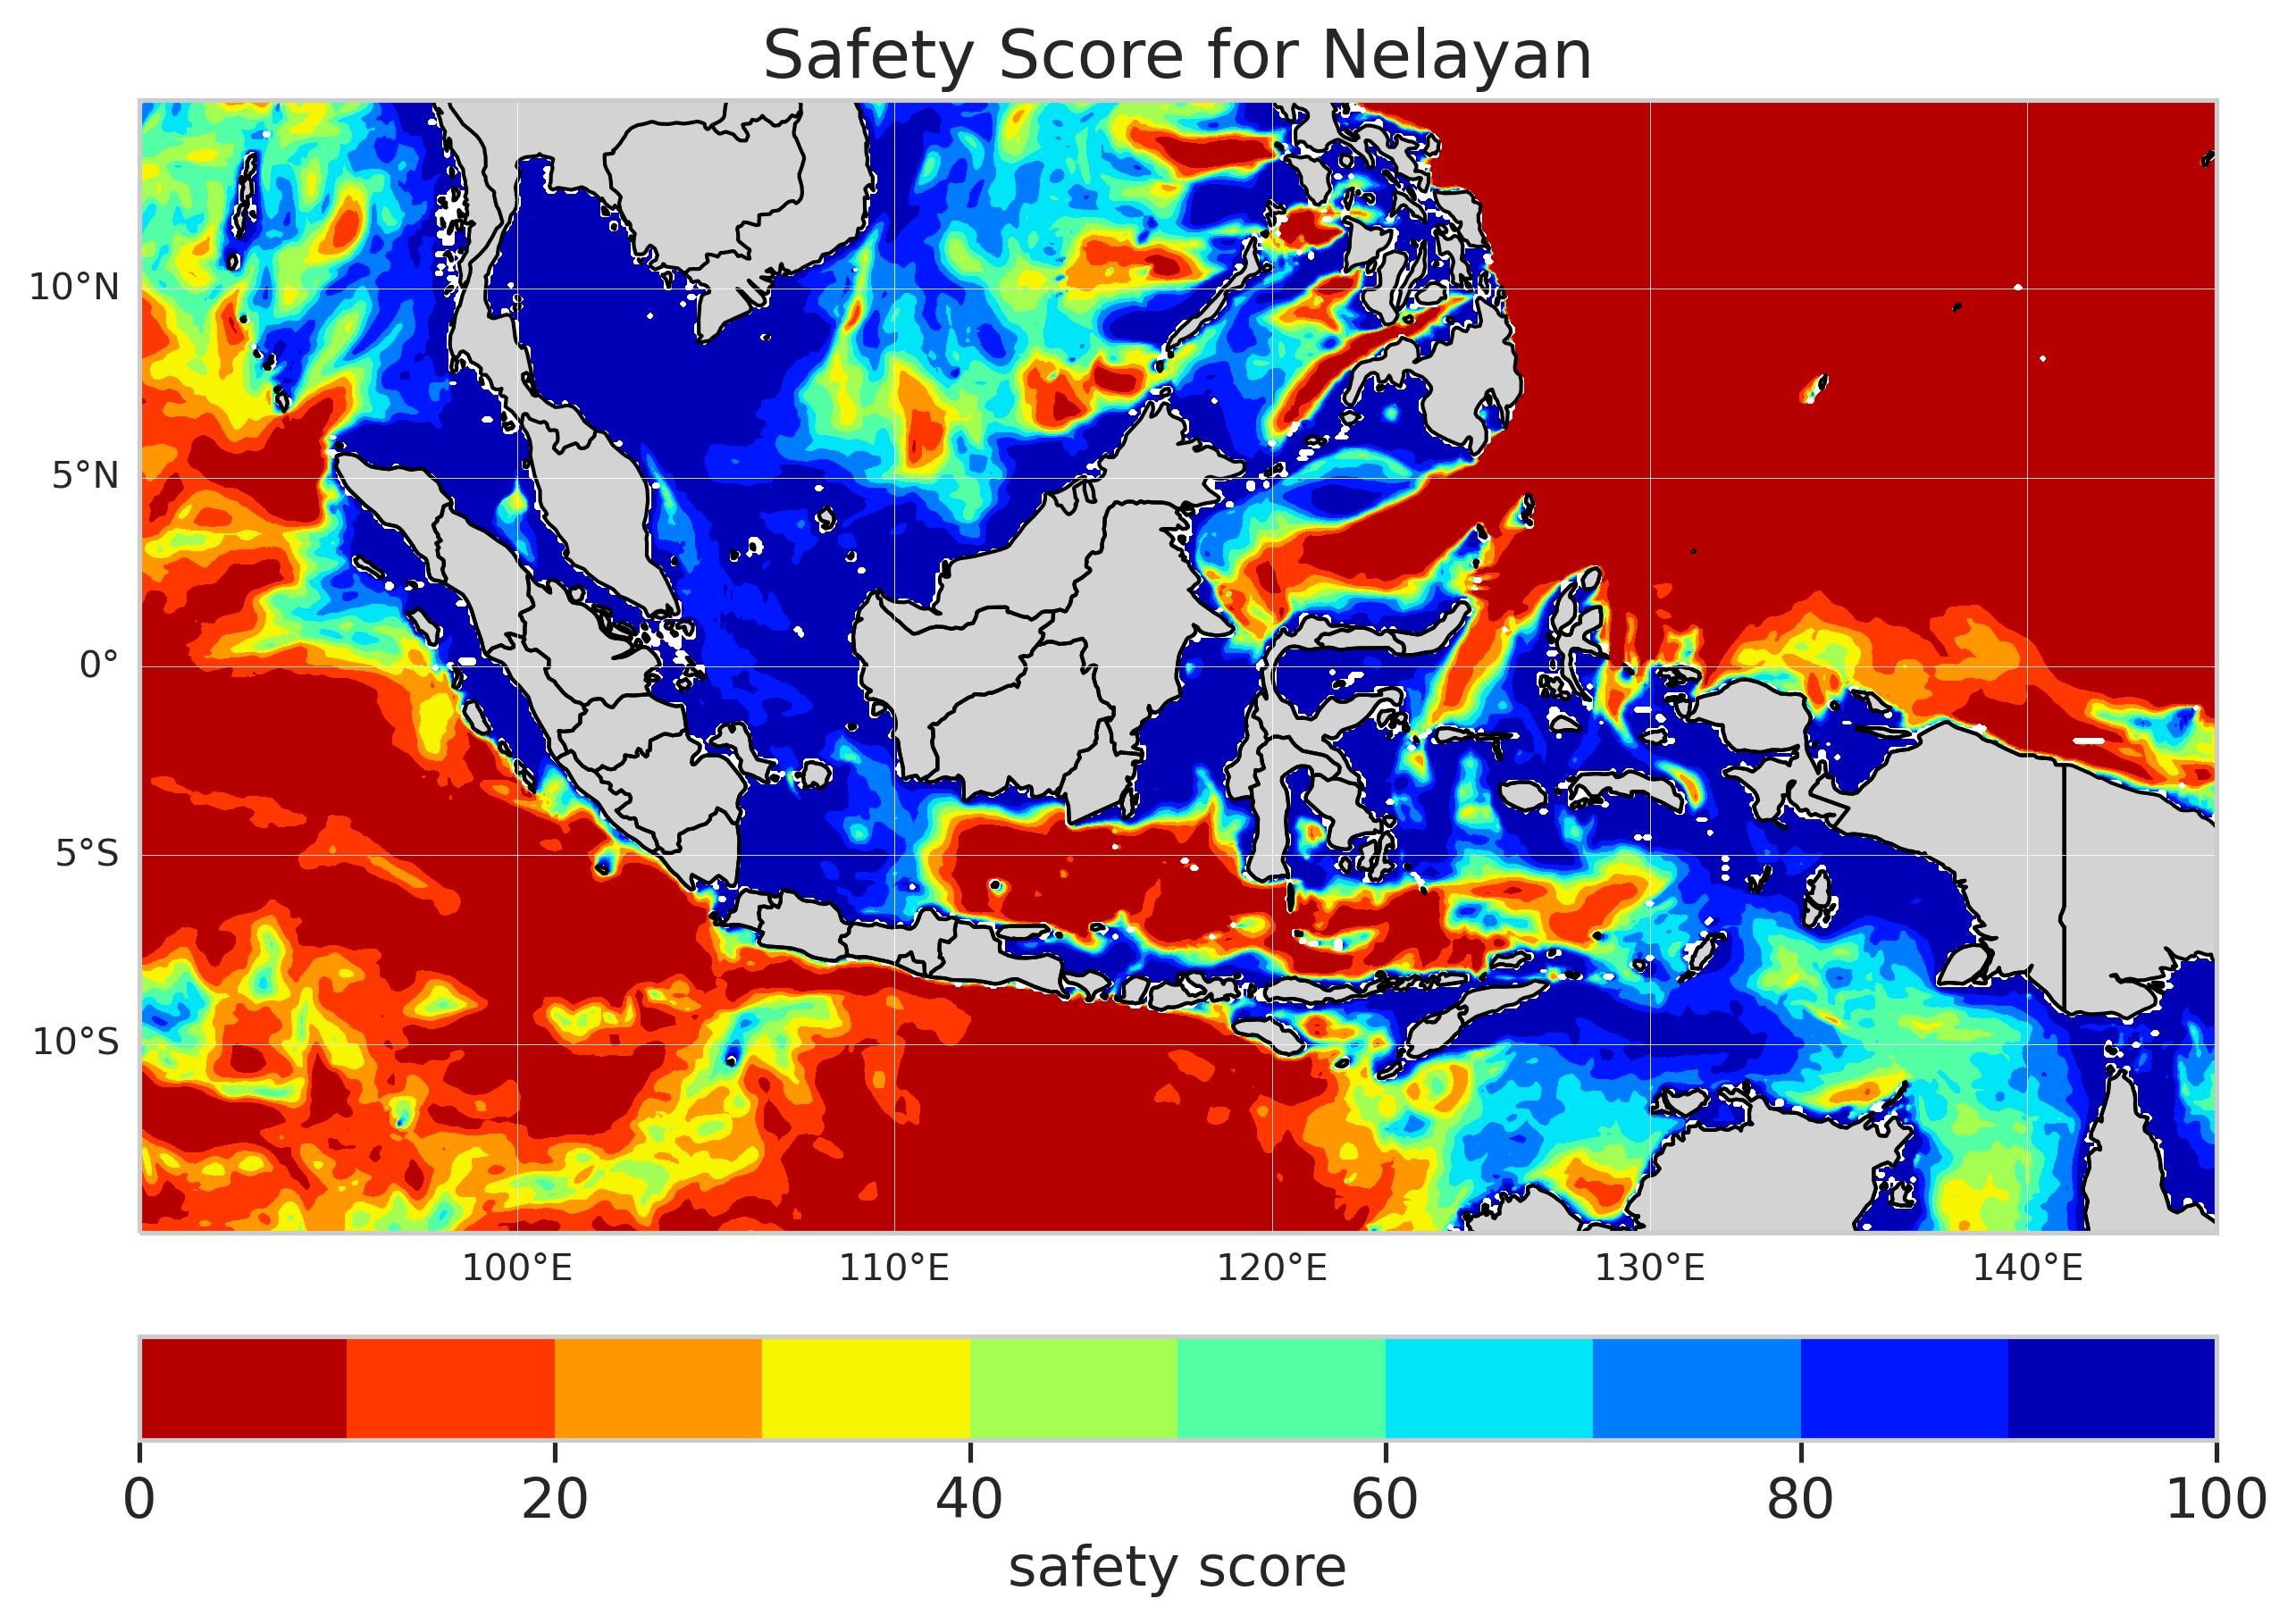

In [ ]:
# plt.figure(figsize=(10, 5), dpi=300)
# pred_dataset['Nelayan'].plot(cmap='jet_r', levels=np.arange(0, 101, 10))

lvl = np.arange(0, 101, 10)
latlon_int = 5
cmap = 'jet_r'
map_title = 'Safety Score for Nelayan'
legend_title = 'safety score'
plot_map_mag(pred_dataset.lat, pred_dataset.lon, latlon_int, cmap, lvl, pred_dataset['Nelayan'], map_title, legend_title)


### Tongkang

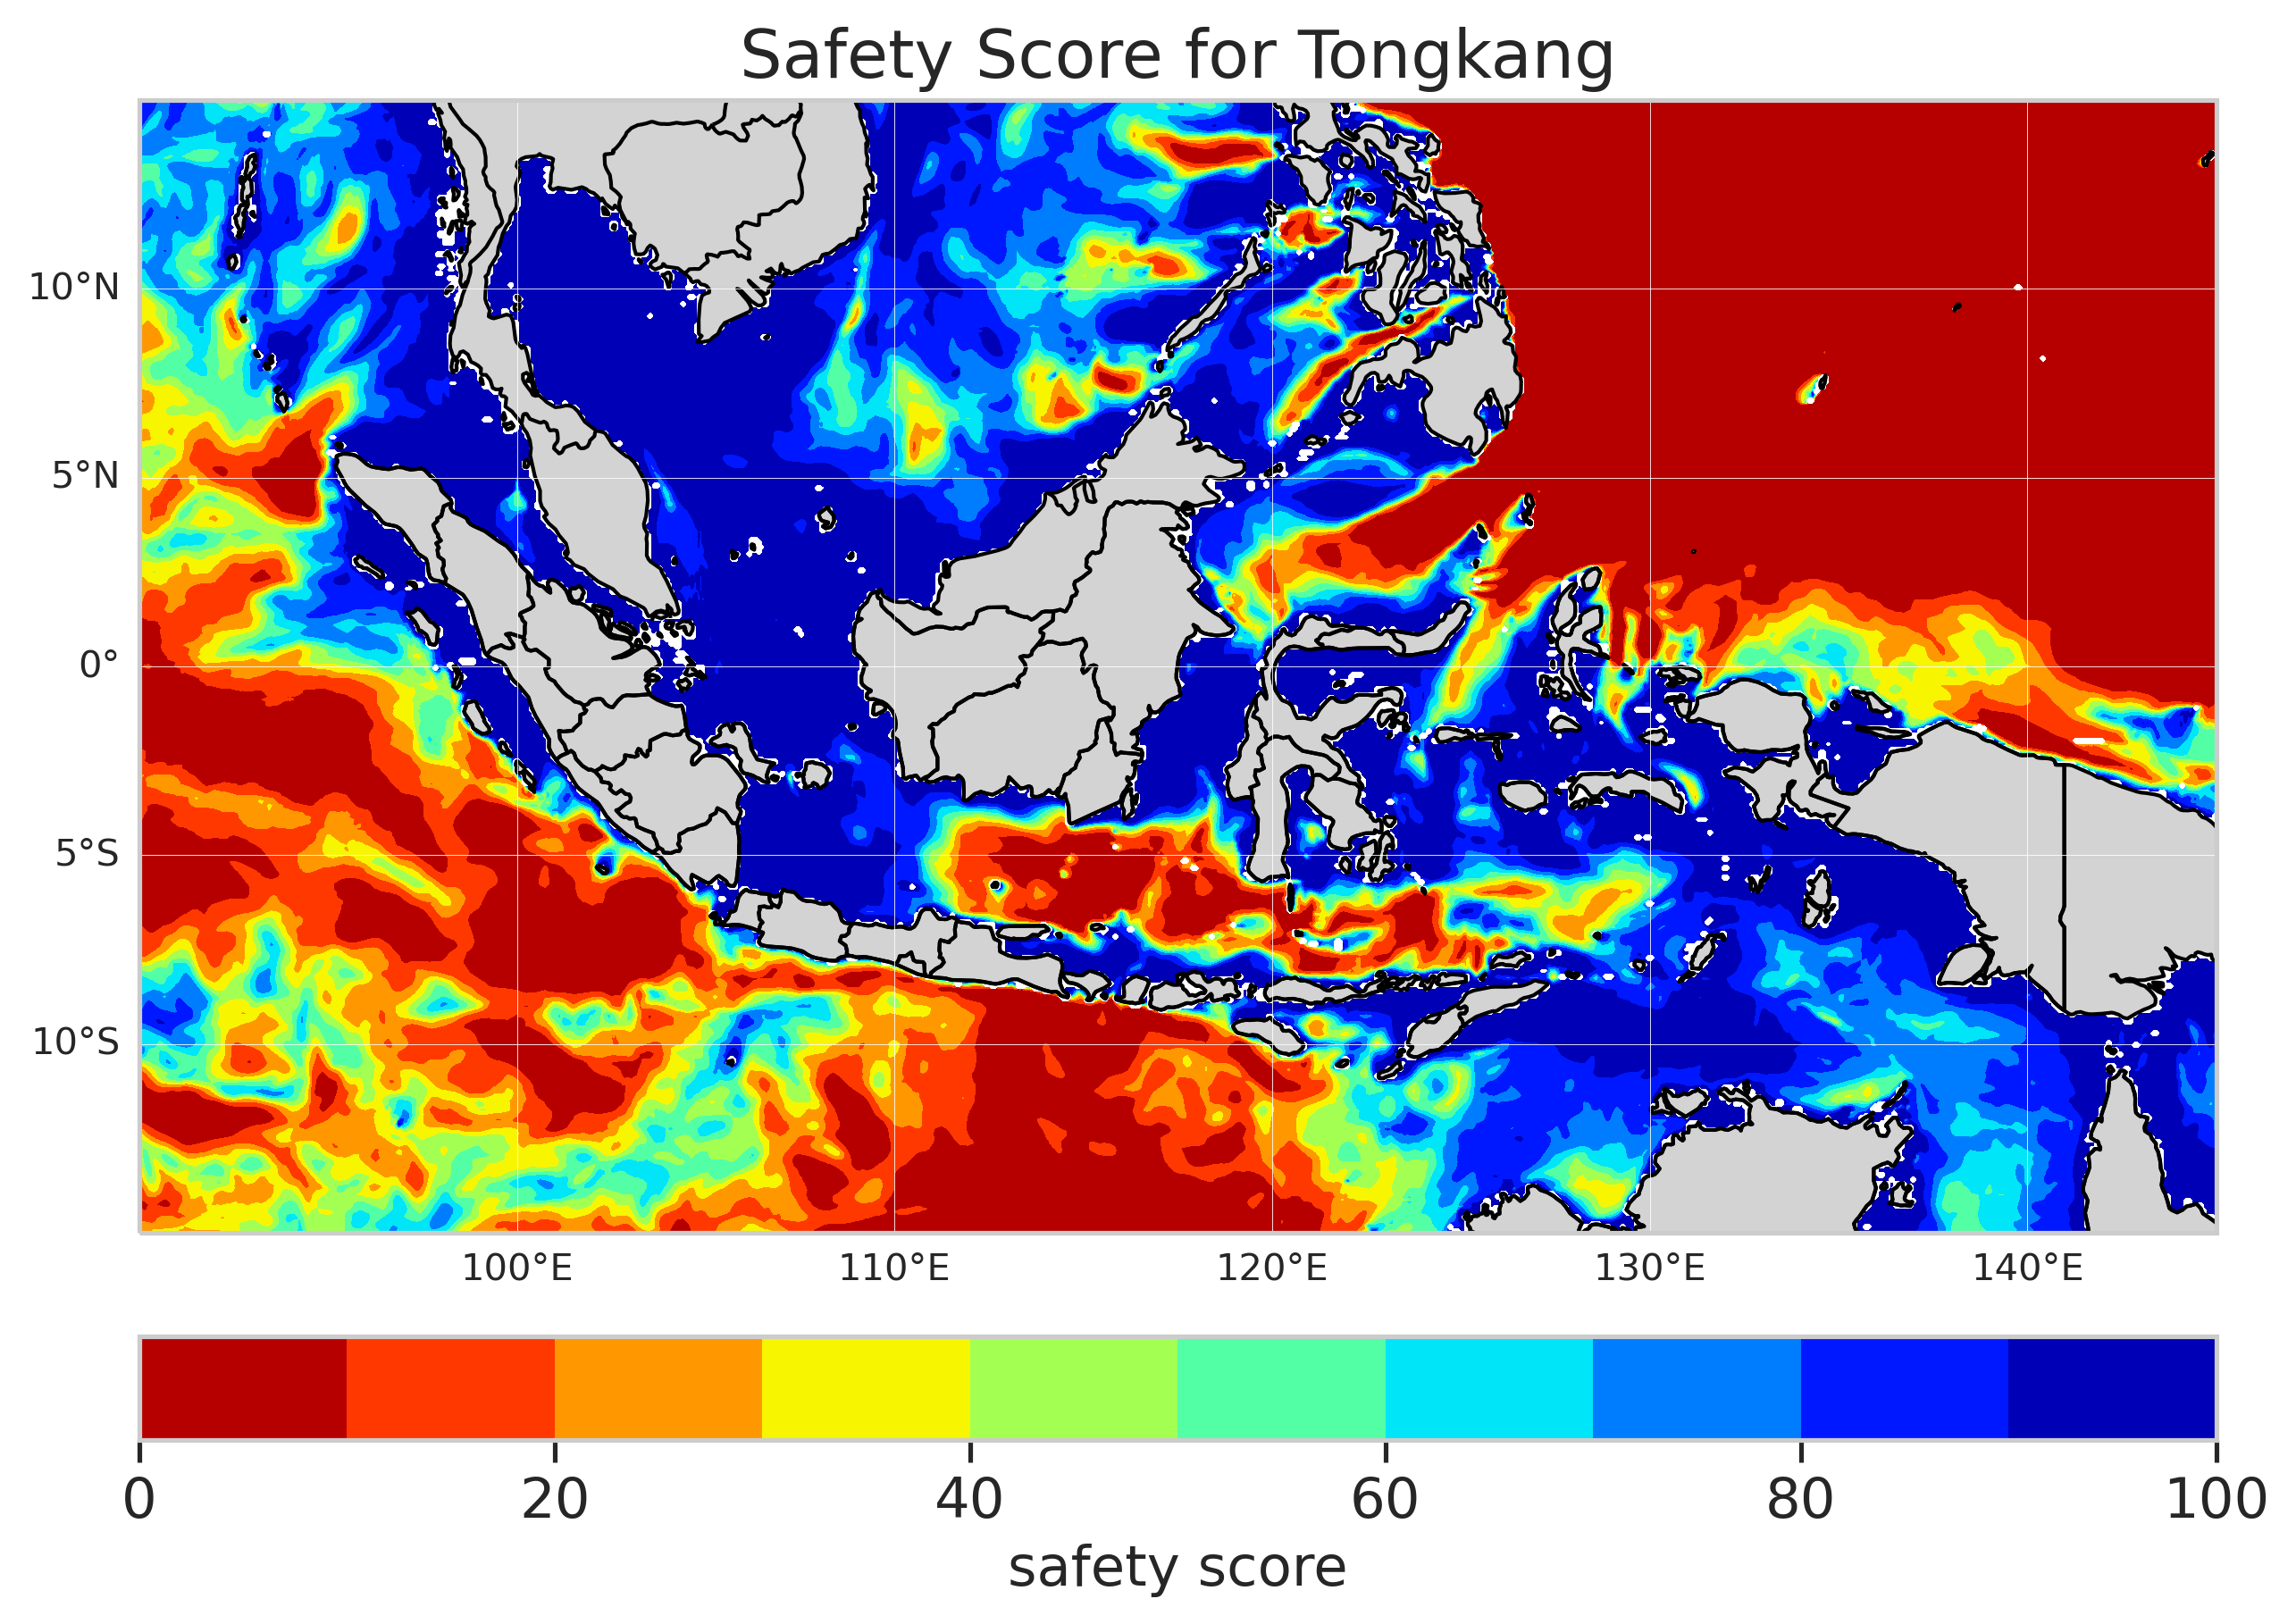

In [ ]:
# plt.figure(figsize=(10, 5), dpi=300)
# pred_dataset['Tongkang'].plot(cmap='jet_r', levels=np.arange(0, 101, 10))

lvl = np.arange(0, 101, 10)
latlon_int = 5
cmap = 'jet_r'
map_title = 'Safety Score for Tongkang'
legend_title = 'safety score'
plot_map_mag(pred_dataset.lat, pred_dataset.lon, latlon_int, cmap, lvl, pred_dataset['Tongkang'], map_title, legend_title)


### Ferry

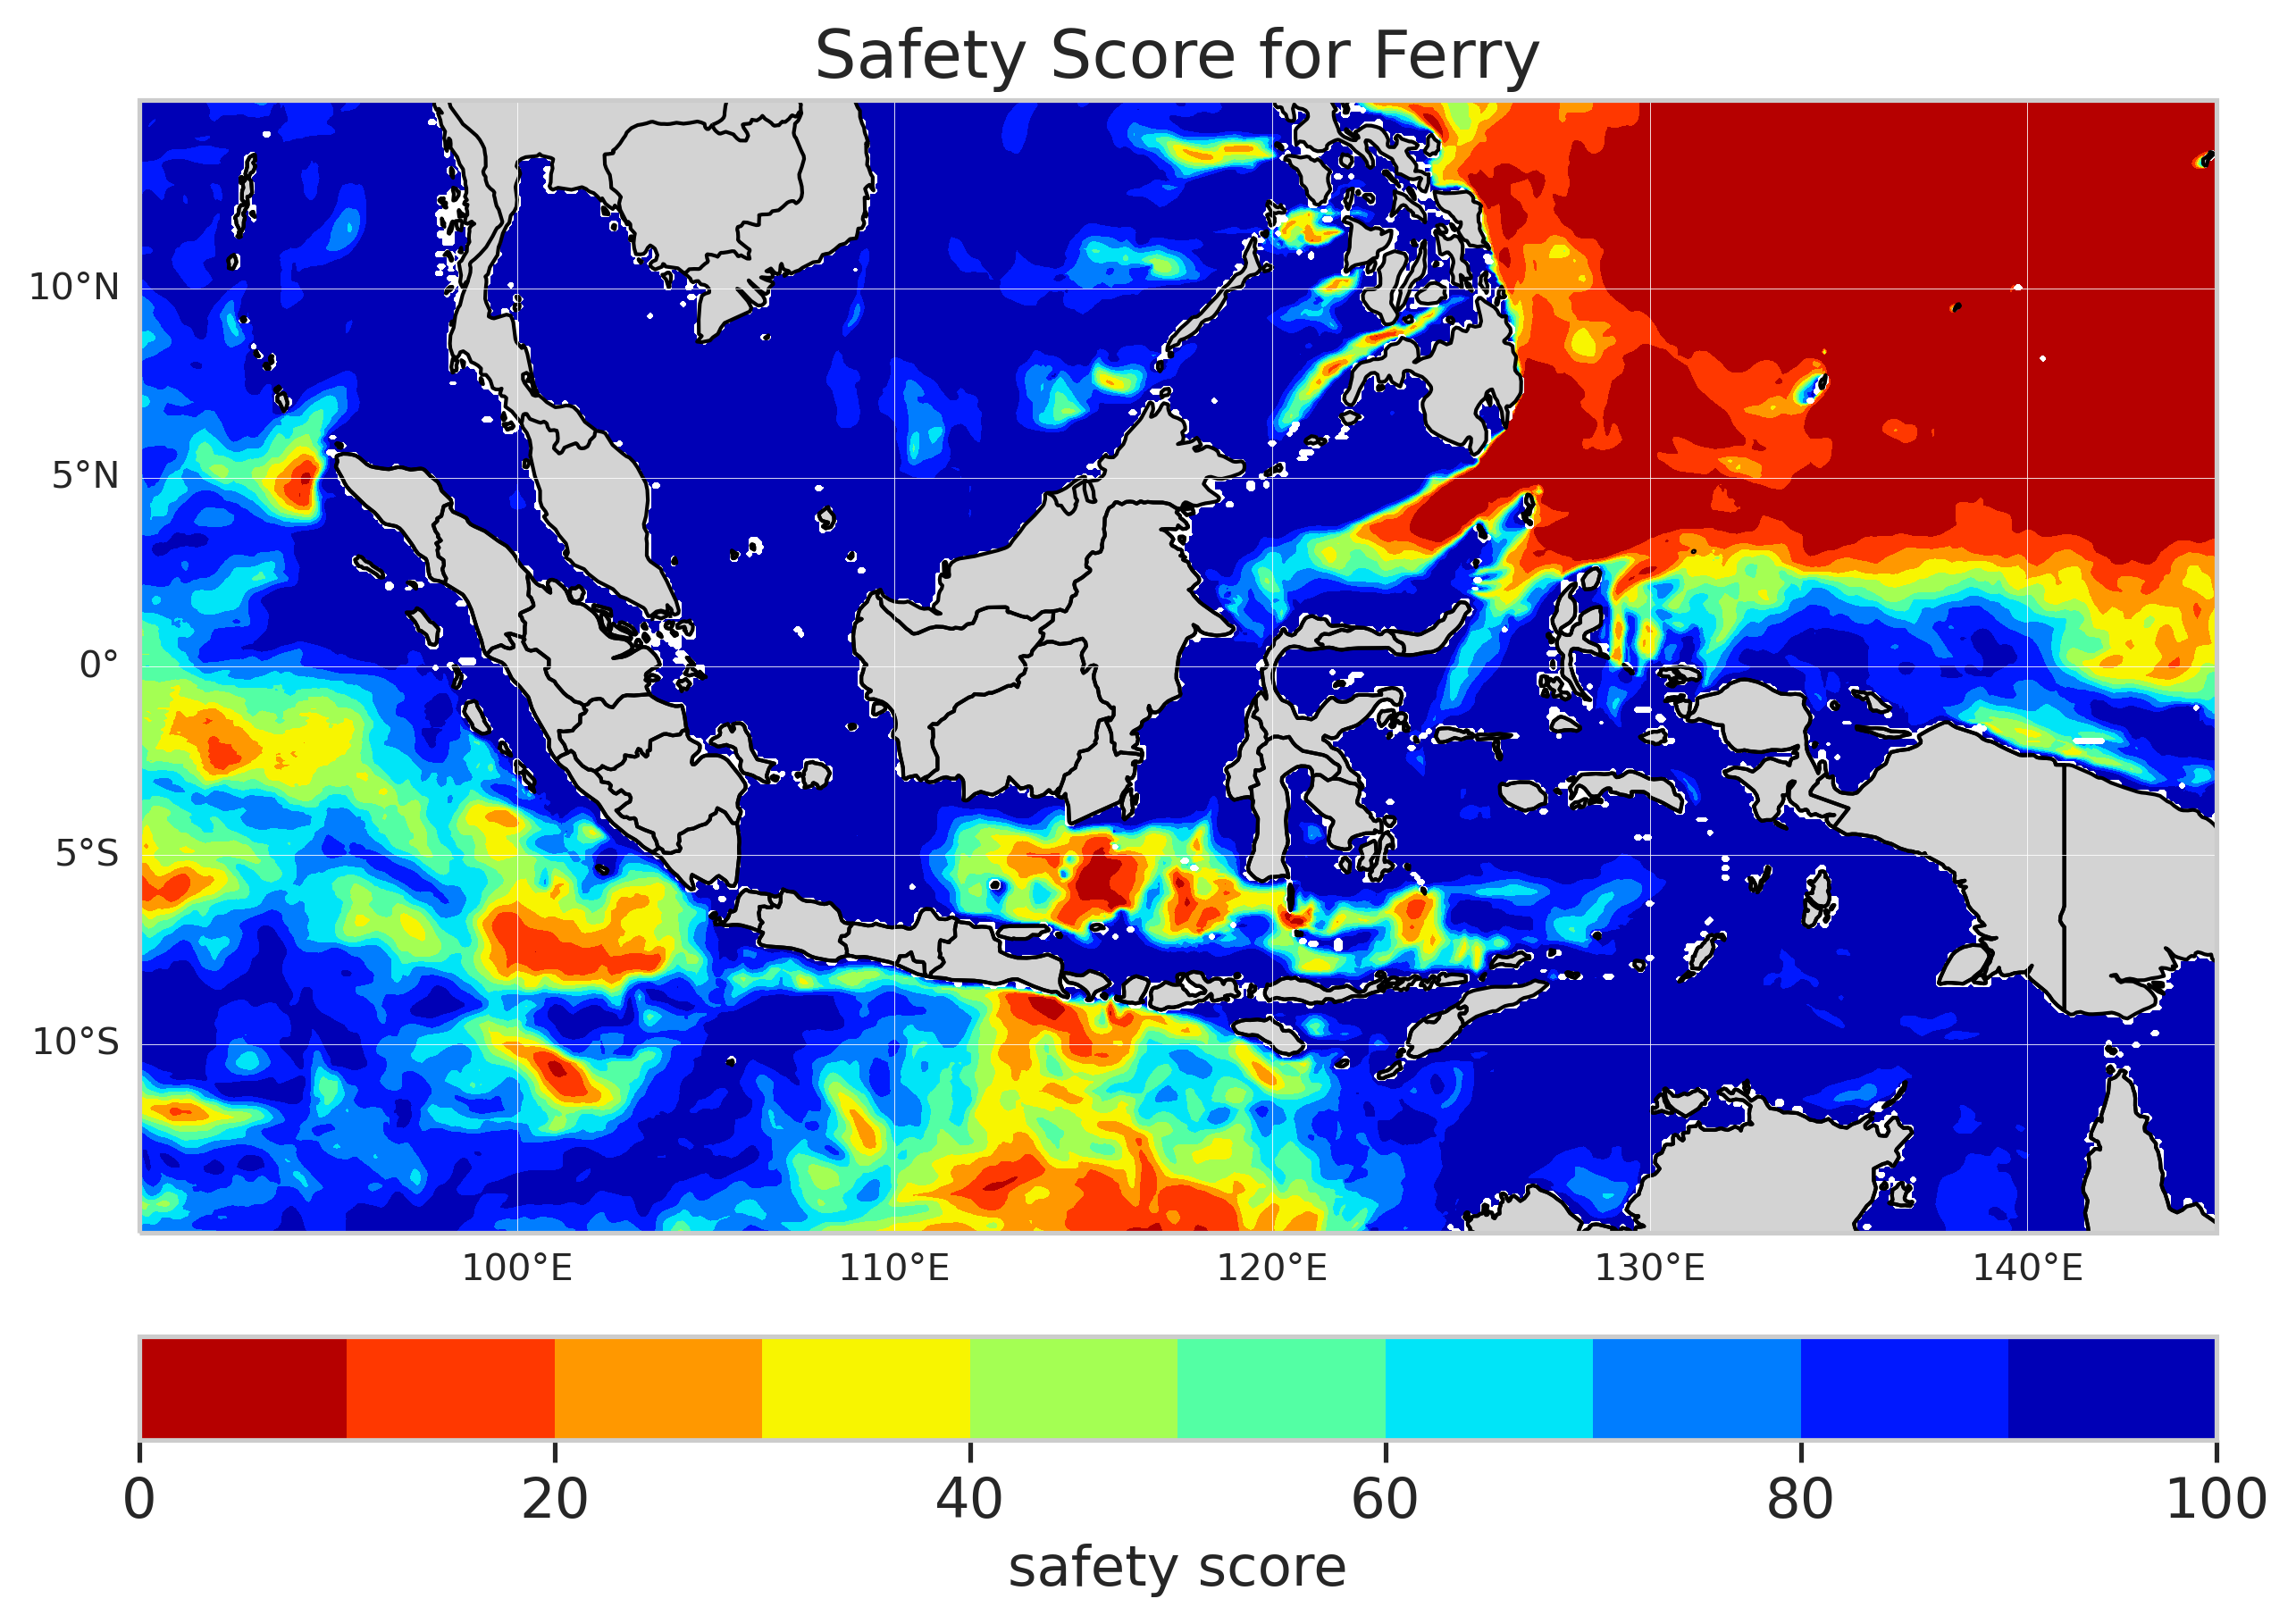

In [ ]:
# plt.figure(figsize=(10, 5), dpi=300)
# pred_dataset['Ferry'].plot(cmap='jet_r', levels=np.arange(0, 101, 10))

lvl = np.arange(0, 101, 10)
latlon_int = 5
cmap = 'jet_r'
map_title = 'Safety Score for Ferry'
legend_title = 'safety score'
plot_map_mag(pred_dataset.lat, pred_dataset.lon, latlon_int, cmap, lvl, pred_dataset['Ferry'], map_title, legend_title)

### Kapal Besar

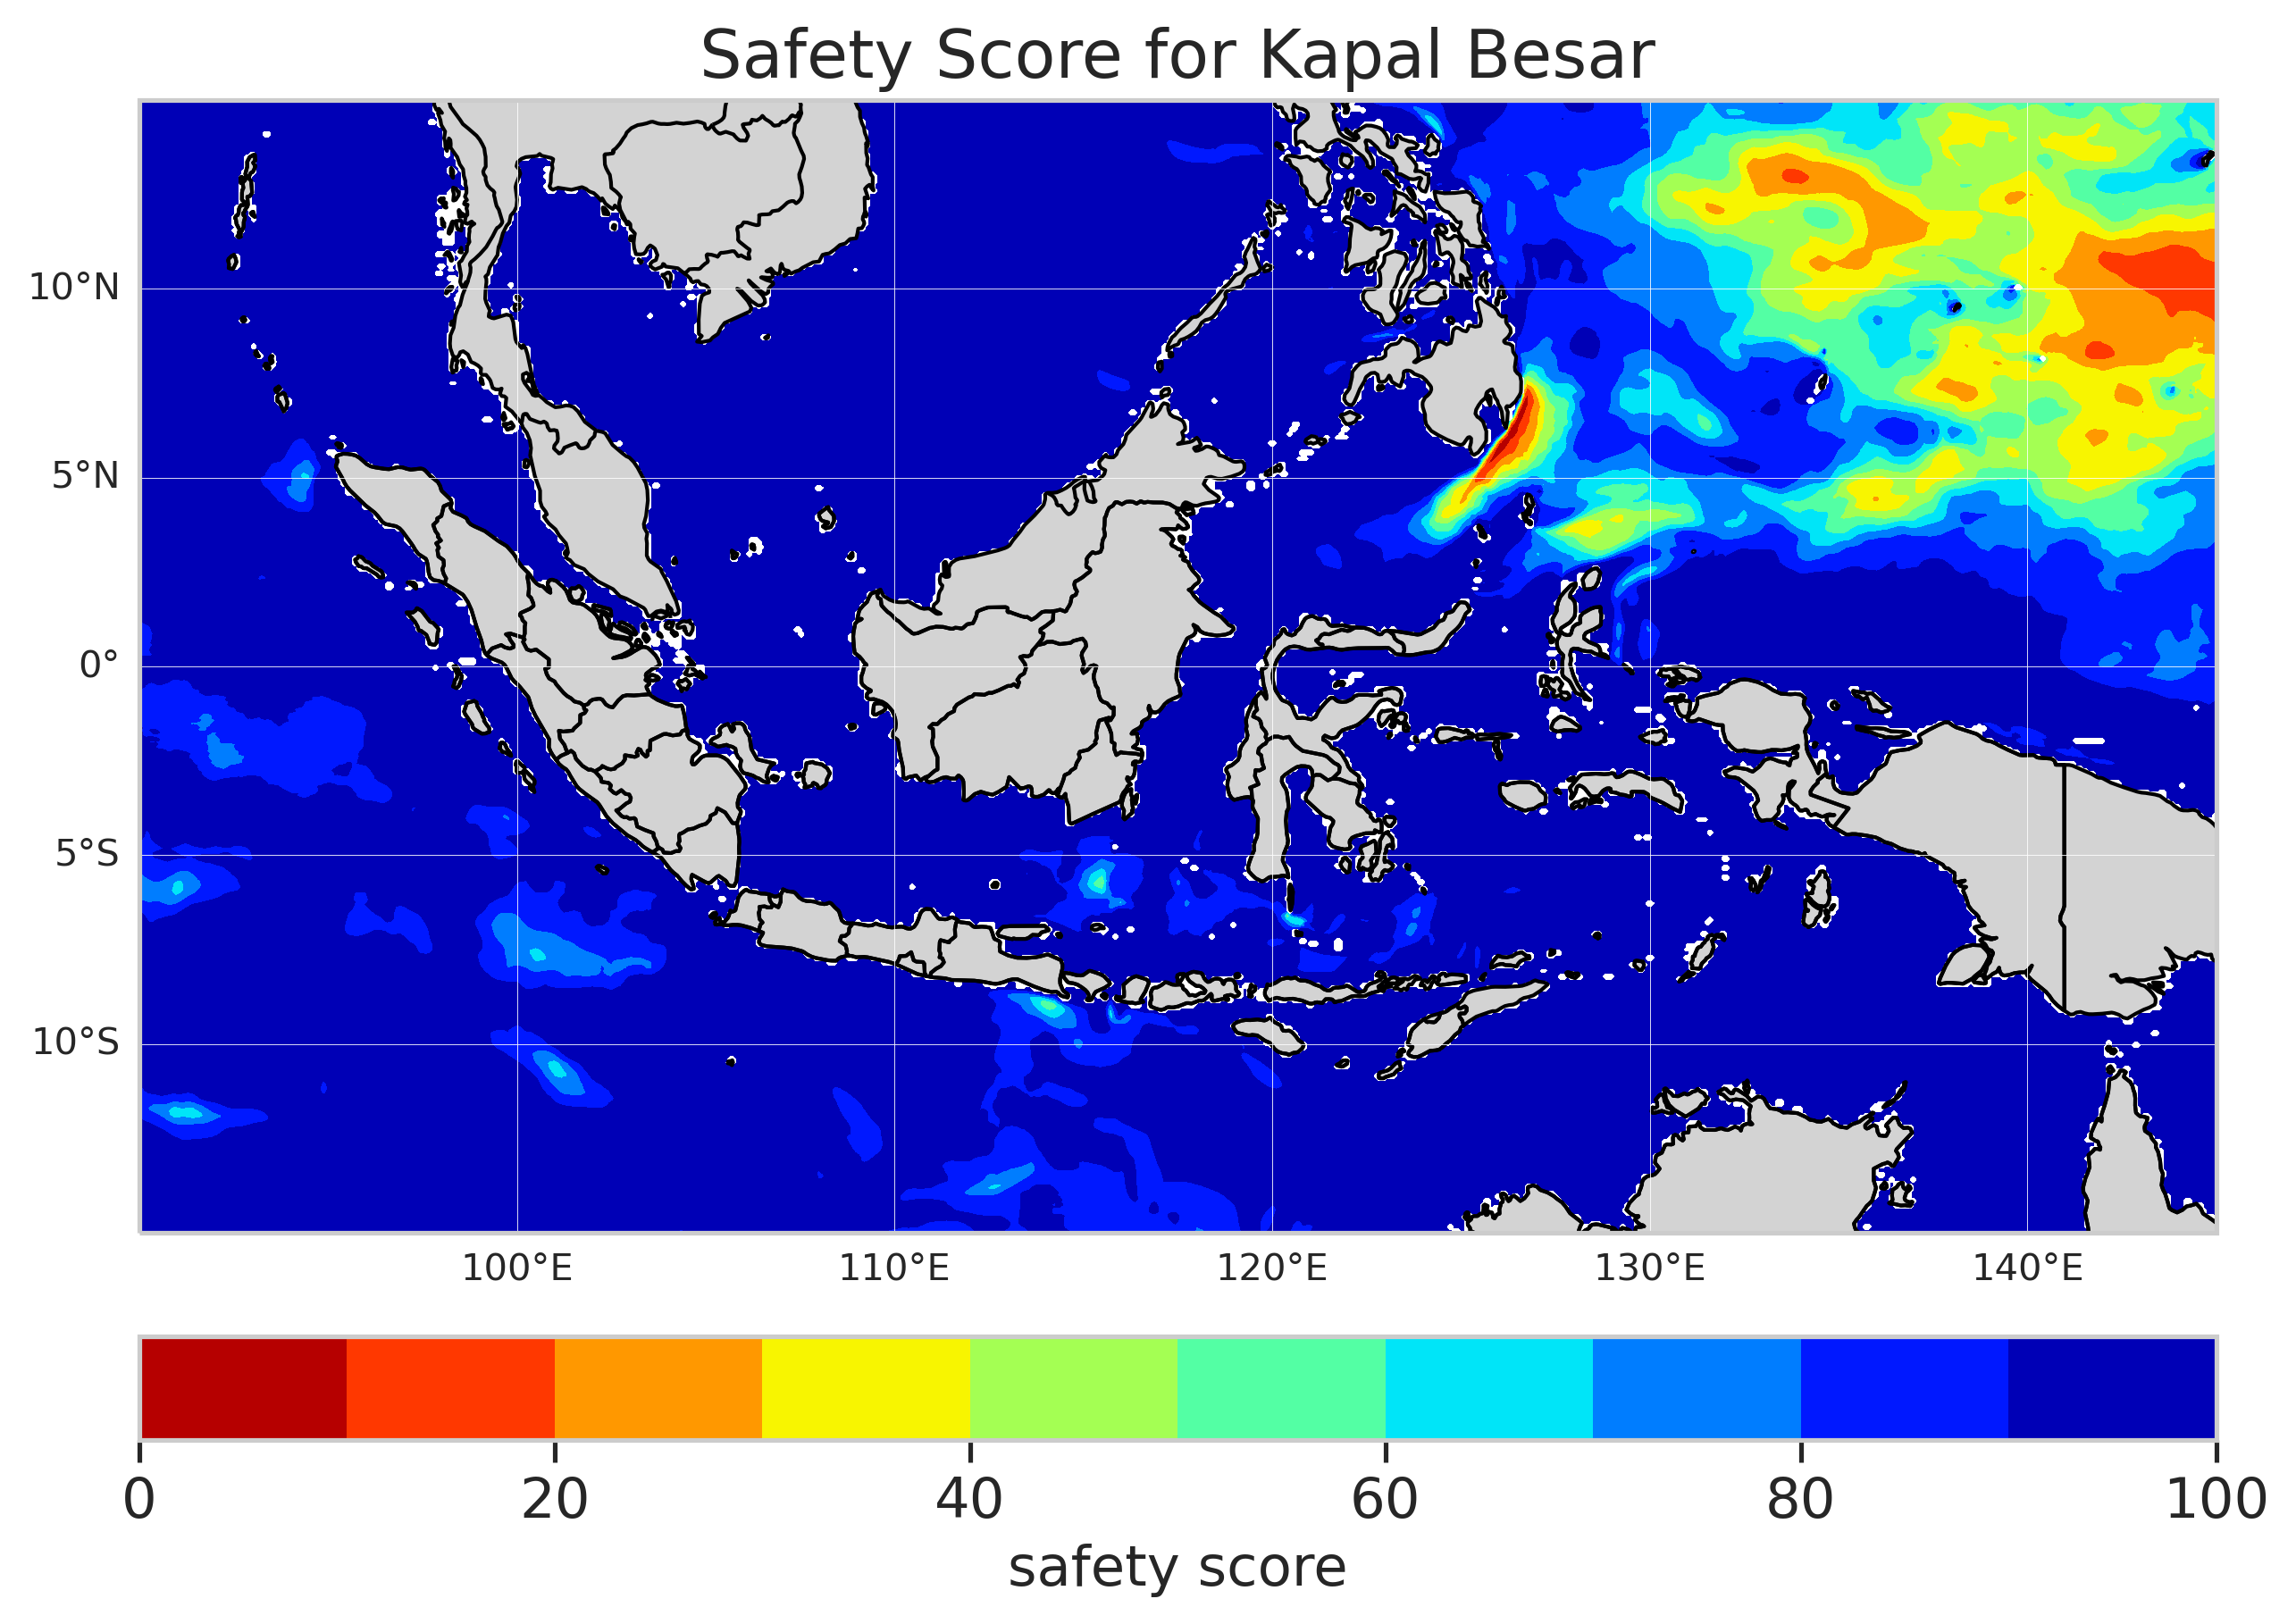

In [ ]:
# plt.figure(figsize=(10, 5), dpi=300)
# pred_dataset['Kapal Besar'].plot(cmap='jet_r', levels=np.arange(0, 101, 10))

lvl = np.arange(0, 101, 10)
latlon_int = 5
cmap = 'jet_r'
map_title = 'Safety Score for Kapal Besar'
legend_title = 'safety score'
plot_map_mag(pred_dataset.lat, pred_dataset.lon, latlon_int, cmap, lvl, pred_dataset['Kapal Besar'], map_title, legend_title)